# ADMM 기반 위성 도킹 MPC: 시간 격자 및 계산 예산 비교

Uniform, Exponential (기존 Geometric, $\gamma=1.08$), Logarithmic ($\beta=0.8$). 모든 모델에 동일한 Braking 제약과 KKT-ADMM을 적용한다. Generalized Exponential 및 내부 검사점 제약은 제외한다. 기본 실험과 추가 민감도 실험을 분리한다.

In [1]:
from dataclasses import dataclass
from pathlib import Path
from time import perf_counter
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import splu
from scipy.linalg import expm
from scipy.optimize import linprog
from functools import lru_cache
import pandas as pd
import matplotlib.pyplot as plt

## 1. 파라미터 및 목적함수
물리 상태 $s=[p_x,p_y,p_z,v_x,v_y,v_z]^T$, 제어 입력 $u_p=[a_x,a_y,a_z]^T$를 사용한다. 목표 상태 $s_r=[2,0,0,0,0,0]^T$이다.

$$J=\int_0^{T_p}[(s-s_r)^TQ(s-s_r)+u_p^TRu_p]dt+(s(T_p)-s_r)^TQ_f(s(T_p)-s_r).$$

위치와 속도의 크기가 다르므로 대각 스케일 행렬 $S_x=\mathrm{diag}(SX)$, $S_u=\mathrm{diag}(SU)$를 사용한다. $s=s_r+S_x x$, $u_p=S_u u$. 따라서 $\bar Q=S_x^TQS_x$, $\bar R=S_u^TRS_u$이다. 초기 상태 표준편차는 실험 가정이다.

In [ ]:
DT = 1.0
N = 25
GAMMA = 1.08
BETA = 0.8
EXPERIMENT = "A"  # A: variable horizon; B: matched nonuniform horizon
A_BRAKE = 0.04
MONTE_CARLO_N = 100
INITIAL_STD = np.array([5.,2.,2.,.05,.03,.03])
SAFE_POS_TOL = SAFE_VEL_TOL = 1e-3
PORT = np.array([2., 0., 0.])
REF = np.r_[PORT, np.zeros(3)]
INITIAL = np.array([50., 5., 3., 0., 0., 0.])
UMAX = .05
ALPHA = .05
THETA = np.deg2rad(20)
CONE = np.tan(THETA) / np.sqrt(2)
POS_TOL, VEL_TOL = .01, .005

# Nondimensional variables: physical state = REF + SX * x, input = SU * u.
SX = np.array([10., 10., 10., .5, .5, .5])
SU = np.full(3, UMAX)
Q = np.diag([1., 10., 10., 5., 5., 5.])
R = 1000 * np.eye(3)
QF = 100 * Q

QUICK = False
TRIALS = 1 if QUICK else MONTE_CARLO_N
DURATION = 5 if QUICK else 300
MAX_ITER = 15000
SEED = 42
OUT = Path('three_grid_comparison_'+EXPERIMENT)
# Additional experiments (independent from baseline)
RUN_SWEEPS = True
SWEEP_TRIALS = 20
N_LIST = [5, 10, 15, 20, 25, 30]
ITER_LIST = [100, 200, 500, 1000, 3000, 15000]
UNCERTAINTY_LIST = [0.5, 1., 2., 3., 4.]
RUN_2D = False  # Enable for the full N × iteration budget heatmap
RUN_MATCHED = True
RUN_GROWTH = True
GAMMA_LIST = [1.02, 1.04, 1.06, 1.08, 1.10, 1.12]
CHECK_LP = True

## 2. Clohessy–Wiltshire 상대운동 방정식
원형 기준 궤도에서 평균 각속도 $n=\sqrt{\mu/r^3}$로 두면
$$\ddot p_x=3n^2p_x+2n\dot p_y+a_x,\quad \ddot p_y=-2n\dot p_x+a_y,\quad \ddot p_z=-n^2p_z+a_z.$$
이를 $\dot s=A_cs+B_cu_p$로 표현한다. 좌표 이동 및 스케일을 대입하면
$$S_x\dot x=A_c(s_r+S_xx)+B_cS_uu,$$
$$\dot x=Ax+Bu+a,\qquad A=S_x^{-1}A_cS_x,\ B=S_x^{-1}B_cS_u,\ a=S_x^{-1}A_cs_r.$$
도킹 포트가 원점이 아니므로 affine term $a$를 제거하면 안 된다.

In [ ]:
n = np.sqrt(3.986004418e14 / (6371e3 + 400e3)**3)
AC = np.zeros((6, 6)); AC[:3, 3:] = np.eye(3)
AC[3, 0] = 3*n*n; AC[3, 4] = 2*n
AC[4, 3] = -2*n; AC[5, 2] = -n*n
BC = np.vstack((np.zeros((3, 3)), np.eye(3)))

# Shift to port-centered coordinates; affine drift must be retained.
A = AC * SX[None, :] / SX[:, None]
B = BC * SU[None, :] / SX[:, None]
a = (AC @ REF) / SX
M = np.zeros((10, 10)); M[:6, :6] = A; M[:6, 6:9] = B; M[:6, 9] = a

## 3. ZOH 이산화
구간 길이 $h_k$ 동안 $u_k$를 고정한다. 해는
$$x_{k+1}=e^{Ah_k}x_k+\int_0^{h_k}e^{A\tau}B\,d\tau\,u_k+\int_0^{h_k}e^{A\tau}a\,d\tau.$$
$A$의 역행렬 없이 세 항을 한 번에 구하려면
$$\exp\left(h_k\begin{bmatrix}A&B&a\\0&0&0\\0&0&0\end{bmatrix}\right)=\begin{bmatrix}F_k&L_k&g_k\\0&I&0\\0&0&1\end{bmatrix}.$$
따라서 $x_{k+1}=F_kx_k+L_ku_k+g_k$.

In [4]:
@lru_cache(maxsize=None)
def discrete(t):
    E = expm(M*t)
    return E[:6, :6], E[:6, 6:9], E[:6, 9]

def advance(x, u, model):
    F, L, g = model
    return F @ x + L @ u + g

## 4. 시간 격자 유도
$k=0,\ldots,N-1$에서 첫 구간은 항상 $h_0=\Delta t=1$초이다.

- Uniform: $h_k=\Delta t$, $T_U=N\Delta t$.
- Exponential (기존 Geometric): $h_k=\Delta t\gamma^k=\Delta t e^{k\ln\gamma}$, $T_E=\Delta t(\gamma^N-1)/(\gamma-1)$.
- Logarithmic: $h_k=\Delta t(1+\beta\ln(1+k))$, $T_L=\Delta t[N+\beta\ln(N!)]$.

실험 A는 기존 파라미터를 유지한다. 실험 B는 Exponential과 Logarithmic의 예측 범위를 맞추기 위해 $\beta=(T_E/\Delta t-N)/\ln(N!)$를 사용한다. Uniform은 첫 구간과 N을 고정한 기준군이므로 동일 범위가 아니다. 일반화 지수함수는 제외한다.

In [5]:
def grid(N, kind, mode=None, gamma=GAMMA, beta=BETA):
    mode = EXPERIMENT if mode is None else mode
    k = np.arange(N, dtype=float)
    if kind == 'uniform': return np.full(N, DT)
    if kind == 'exponential': return DT * gamma**k
    if kind == 'logarithmic':
        if mode == 'B':
            beta = (np.sum(gamma**k)-N)/np.log1p(k).sum()
        return DT * (1 + beta*np.log1p(k))
    raise ValueError(kind)

assert EXPERIMENT in ('A','B') and N>1 and GAMMA>=1 and BETA>=0
for kind in ['uniform','exponential','logarithmic']:
    h = grid(N,kind)
    assert len(h)==N and np.isclose(h[0],DT)
    print(f'{kind:15s} horizon={h.sum():.3f} s, max dt={h.max():.3f} s')

uniform         horizon=25.000 s, max dt=1.000 s
exponential     horizon=73.106 s, max dt=6.341 s
logarithmic     horizon=71.403 s, max dt=3.575 s


## 5. 공통 도킹 제약조건
포트 기준 물리 위치를 $(d,y,z)$라 하고 접근 속도를 $v=-v_x$라 한다. 사각뿔 $|y|,|z|\le cd$, $c=\tan\theta/\sqrt2$는 원형 접근 원뿔 안에 포함된다. 또한 $d\ge0$, $0\le v\le\alpha d$를 적용한다.

선형 속도 경계 $v=\alpha d$에서 $\dot d=-v$이므로 필요한 감속도 크기는 $\alpha v$. 따라서 가용 감속도 $a_b$를 고려하여 모든 모델에서
$$0\le v\le\min(\alpha d,a_b/\alpha)$$
를 적용한다. 두 상한을 곱하면 $v^2\le a_bd$이므로 단순 축방향 일정 감속 모델에서는 $d_{stop}=v^2/(2a_b)\le d/2$이다. 제곱근 제약을 별도로 추가할 필요가 없다. 단, CW 교차항과 구간 내부 변화 때문에 실제 연속시간 안전성이 증명되는 것은 아니다.

행렬로 표현하면 $C_p(s-s_r)\le h_p$. 스케일링 후 각 행을 양의 행 노름으로 나누어 $C_s x\le h_s$를 얻는다. 아래 기본 행렬에 Solver가 속도 상한 행을 추가한다.

In [6]:
# C @ physical port-relative state <= 0: corridor, halfspace, speed.
C = np.array([[-CONE, 1,0,0,0,0], [-CONE,-1,0,0,0,0],
              [-CONE,0,1,0,0,0], [-CONE,0,-1,0,0,0],
              [-1,0,0,0,0,0], [0,0,0,1,0,0],
              [-ALPHA,0,0,-1,0,0]])
CS = C * SX
CS /= np.linalg.norm(CS, axis=1)[:, None]

@dataclass
class Case:
    name: str
    dt: np.ndarray


## 6. QP 구성과 ADMM Solver
### 6.1 최적화 변수와 등식 제약
$$w=[x_1^T,\ldots,x_N^T,u_0^T,\ldots,u_{N-1}^T]^T\in\mathbb R^{9N}.$$
각 구간의 동역학을 $x_{k+1}-F_kx_k-L_ku_k=g_k$로 옮기면 $Gw=b$이다. 첫 구간의 $x_0$는 알려진 값이므로 우변은 $g_0+F_0x_0$이다. $G\in\mathbb R^{6N\times9N}$.

### 6.2 목적함수 행렬 유도
구간 내 상태를 $x(t_k+\tau)=E(\tau)w+c(\tau)$로 나타내면
$$x^T\bar Qx=w^TE^T\bar QEw+2c^T\bar QEw+c^T\bar Qc.$$
상수항을 제외하고 $J=\frac12w^THw+f^Tw$ 형태로 정리한다. 각 적분점의 가중치 $\omega$에 대해 $H\mathrel{+}=2\omega E^T\bar QE$, $f\mathrel{+}=2\omega E^T\bar Qc$. 제어 비용은 $2h_k\bar R$, 종단 비용은 $2S_x^TQ_fS_x$를 해당 Hessian 블록에 더한다. 첫 구간의 $c=F(\tau)x_0+g(\tau)$이므로 $f$의 초기 상태 의존항을 별도로 저장한다.

Gauss–Legendre 5점 적분은 $\int_0^{h}f(\tau)d\tau\approx\frac h2\sum_i\omega_i f(h(\xi_i+1)/2)$를 사용한다. 전체 목적함수를 100으로 나누는 것은 최적해를 바꾸지 않는다.

### 6.3 부등식 제약
입력은 $-1\le u_k\le1$, 상태는 $C_sx_{k+1}\le h_s$. 모든 행을 모아 $l\le Dw\le h$로 구성한다. 내부 검사점은 최적화에 추가하지 않는다. 상태 제약 8개와 입력 제약 행 3개로 $D\in\mathbb R^{11N\times9N}$이다. 모든 방식에서 같은 차원을 유지한다.

### 6.4 KKT 및 ADMM 유도
$z=Dw$로 분리하고 scaled dual $\lambda$를 두면 augmented Lagrangian은
$$\mathcal L_\rho=\tfrac12w^THw+f^Tw+I_{[l,h]}(z)+\tfrac\rho2\|Dw-z+\lambda\|^2-\tfrac\rho2\|\lambda\|^2.$$
$Gw=b$를 유지하며 $w$에 대해 미분하면
$$\begin{bmatrix}H+\rho D^TD&G^T\\G&0\end{bmatrix}\begin{bmatrix}w^{j+1}\\\nu^{j+1}\end{bmatrix}=\begin{bmatrix}-f+\rho D^T(z^j-\lambda^j)\\b\end{bmatrix}.$$
KKT 차원은 $15N\times15N$이다. 희소 LU 분해를 재사용한다. Over-relaxation $\hat d=1.6Dw^{j+1}-0.6z^j$ 이후
$$z^{j+1}=\mathrm{clip}(\hat d+\lambda^j,l,h),\qquad \lambda^{j+1}=\lambda^j+\hat d-z^{j+1}.$$
수렴 검사: primal $\|Dw-z\|_\infty$, dual 변화량 $\rho\|D^T(z-z_{old})\|_\infty$, stationarity $\|Hw+f+G^T\nu+\rho D^T\lambda\|_\infty$, equality $\|Gw-b\|_\infty$. 100회마다 residual balancing을 적용하고 $\rho$가 변경되면 $\lambda\leftarrow(\rho_{old}/\rho_{new})\lambda$로 조정한다. 아래 클래스는 행렬 구성부터 반복 최적화까지 포함한다.

In [7]:
class Solver:
    def __init__(self, case, rho=10.):
        self.case = case; self.N = N = len(case.dt); self.nw = nw = 9*N
        self.rho = rho
        # The cap v <= a_b / alpha makes v^2 <= a_b*d redundant
        # when v <= alpha*d. No extra piecewise square-root rows needed.
        C_local = C.copy()
        bound = np.zeros(len(C_local))
        C_local = np.vstack([C_local, [0,0,0,-1,0,0]])
        bound = np.r_[bound, A_BRAKE/ALPHA]
        CS = C_local * SX
        scale = np.linalg.norm(CS, axis=1)
        CS /= scale[:, None]
        bound /= scale
        nc = len(bound)
        self.models = [discrete(t) for t in case.dt]
        # w = [x1,...,xN,u0,...,u(N-1)]. Sparse multiple shooting.
        def xs(k): return slice(6*(k-1), 6*k)
        def us(k): return slice(6*N+3*k, 6*N+3*(k+1))
        self.us = us
        G = sp.lil_matrix((6*N, nw)); b = np.zeros(6*N)
        # Integrate tracking cost over each ZOH interval; xN terminal cost.
        qscaled = SX[:,None]*Q*SX[None,:]
        rscaled = SU[:,None]*R*SU[None,:]
        # Normalize entire objective by a constant (same optimum).
        # R has physical units; use a moderate input penalty for conditioning.
        # ZOH trajectory cost integrated using Gauss-Legendre quadrature.
        H = sp.lil_matrix((nw,nw)); f = np.zeros(nw)
        self.initial_cost_cross = np.zeros((nw,6))
        nodes, weights = np.polynomial.legendre.leggauss(5)
        rows=[]; lows=[]; highs=[]; initial_rows=[]
        def add(blocks, lo, hi, x0coef=None):
            mat = sp.lil_matrix((len(lo),nw))
            for sl, val in blocks: mat[:,sl] = val
            rows.append(mat.tocsc()); lows.extend(lo); highs.extend(hi)
            initial_rows.append(np.zeros((len(lo),6)) if x0coef is None else x0coef)
        for k,(F,L,g) in enumerate(self.models):
            rr = slice(6*k,6*(k+1)); G[rr,xs(k+1)] = np.eye(6)
            G[rr,us(k)] = -L; b[rr] = g
            if k: G[rr,xs(k)] = -F
            add([(us(k),np.eye(3))], -np.ones(3),np.ones(3))
            add([(xs(k+1),CS)], np.full(nc,-np.inf),bound)
            # Integrate physical tracking and effort over the actual interval.
            H[us(k),us(k)] += 2*case.dt[k]*rscaled
            for xi,wi in zip(nodes,weights):
                Ft,Lt,gt = discrete(case.dt[k]*(xi+1)/2)
                wt = case.dt[k]*wi/2
                blocks = [(us(k),Lt)]
                if k: blocks.append((xs(k),Ft))
                for si,Mi in blocks:
                    f[si] += 2*wt*Mi.T@qscaled@gt
                    if not k: self.initial_cost_cross[si] += 2*wt*Mi.T@qscaled@Ft
                    for sj,Mj in blocks:
                        H[si,sj] += 2*wt*Mi.T@qscaled@Mj
        H[xs(N),xs(N)] += 2*(SX[:,None]*QF*SX[None,:])
        self.H = H.tocsc()/100; self.f = f/100; self.initial_cost_cross /= 100
        self.G = G.tocsc(); self.b = b
        self.D = sp.vstack(rows,format='csc'); self.DT = self.D.T.tocsc()
        self.lo = np.array(lows); self.hi = np.array(highs)
        self.initial_rows = np.vstack(initial_rows)
        # Normalize constraint rows to balance ADMM residuals across units.
        self.z = np.zeros(self.D.shape[0]); self.lam = self.z.copy()
        self.DTD = self.DT@self.D
        self.factor_time = 0.; self.factorize()
    def factorize(self):
        t = perf_counter()
        self.KKT = sp.bmat([[self.H+self.rho*self.DTD,self.G.T],
                            [self.G,None]],format='csc')
        self.factor = splu(self.KKT)
        self.factor_time += perf_counter()-t
    def solve(self,x0,max_iter=3000,tol=1e-4):
        t = perf_counter(); b=self.b.copy(); b[:6] += self.models[0][0]@x0
        f=self.f+self.initial_cost_cross@x0
        hi=self.hi-self.initial_rows@x0; lo=self.lo-self.initial_rows@x0
        z=np.clip(self.z,lo,hi); lam=self.lam.copy(); hist=[]
        converged=False
        for j in range(max_iter):
            result=self.factor.solve(np.r_[-f+self.rho*(self.DT@(z-lam)),b]); w=result[:self.nw]; nu=result[self.nw:]
            dw=self.D@w; zp=z
            z=np.clip(1.6*dw-.6*zp+lam,lo,hi); lam += 1.6*dw-.6*zp-z
            r=np.linalg.norm(dw-z,np.inf)
            s=np.linalg.norm(self.rho*(self.DT@(z-zp)),np.inf)
            stationarity=np.linalg.norm(self.H@w+f+self.G.T@nu+self.rho*self.DT@lam,np.inf)
            equality=np.linalg.norm(self.G@w-b,np.inf)
            hist.append((r,s,stationarity,equality))
            if max(r,s,stationarity,equality)<=tol:
                converged=True; break
            # Residual balancing, scaled dual must be adjusted when rho changes.
            if (j+1)%100==0:
                old=self.rho
                if r>10*s: self.rho=min(old*2,1e5)
                elif s>10*r: self.rho=max(old/2,1e-3)
                if old!=self.rho:
                    lam*=old/self.rho; self.factorize()
        self.z=z; self.lam=lam
        return w,converged,np.asarray(hist),perf_counter()-t

## 7. 제약 위반량 및 Feasibility 검사
사각뿔 위반량 $[\max(|y|,|z|)-cd]_+$, 충돌 평면 위반량 $[-d]_+$, 이동 방향 위반량 $[v_x]_+$, 접근 속도 위반량 $[\max(-v_x-\alpha d,-v_x-a_b/\alpha)]_+$를 검사한다. $[q]_+=\max(q,0)$. 예측 궤적은 최대 0.25초 간격, 실제 적용 궤적은 0.1초 간격으로 검사한다. 유한 표본 검사이므로 연속시간 보장은 아니다.

ADMM 실패 시 목적함수를 0으로 둔 LP를 풀어 $Gw=b$, $l\le Dw\le h$의 실행 가능성을 검사한다. LP feasible이면 ADMM의 수렴 실패와 문제 자체의 infeasibility를 구분할 수 있다.

In [8]:
# Audit actual trajectory at 0.1 s, and planned trajectory at <=0.25 s.
def violations(x):
    d=x[:3]*SX[:3]; v=x[3:]*SX[3:]
    return np.maximum([np.max(np.abs(d[1:]))-CONE*d[0],
                       -d[0],v[0],max(-v[0]-ALPHA*d[0], -v[0]-A_BRAKE/ALPHA)],0)

def plan_audit(solver,x,w):
    states=w[:6*solver.N].reshape(-1,6); controls=w[6*solver.N:].reshape(-1,3)
    worst=np.zeros(4)
    for k,h in enumerate(solver.case.dt):
        xk=x if k==0 else states[k-1]
        # Cache exact audit matrices; reuse in every MPC iteration.
        for model in solver.audit_models[k]:
            worst=np.maximum(worst,violations(advance(xk,controls[k],model)))
    return worst

def check_feasibility(solver,x):
    b=solver.b.copy(); b[:6]+=solver.models[0][0]@x
    lo=solver.lo-solver.initial_rows@x; hi=solver.hi-solver.initial_rows@x
    upper=np.isfinite(hi); lower=np.isfinite(lo)
    result=linprog(np.zeros(solver.nw), A_ub=sp.vstack([solver.D[upper],-solver.D[lower]],format='csc'),
        b_ub=np.r_[hi[upper],-lo[lower]], A_eq=solver.G,b_eq=b,
        bounds=[(None,None)]*solver.nw,method='highs')
    return {0:'feasible',2:'infeasible'}.get(result.status,f'LP status {result.status}')


## 8. Receding Horizon MPC
현재 상태 $x_k$로 QP를 풀고 첫 제어 입력만 $\Delta t=1$초 동안 적용한다. 다음 상태를 ZOH로 갱신한 뒤 다시 최적화한다. $\|p-p_r\|_2\le0.01$ m와 $\|v\|_2\le0.005$ m/s를 동시에 만족하면 성공으로 정의한다. 이는 실제 접촉이나 자세 정렬을 모델링한 것이 아니다.

In [9]:
def simulate(case, duration, max_iter, initial, verbose=True):
    solver=Solver(case)
    solver.audit_models=[[discrete(t) for t in np.linspace(0,h,int(np.ceil(h/.25))+1)] for h in case.dt]
    x=(initial-REF)/SX; states=[x*SX+REF]; controls=[]; times=[]; iters=[]; residual=[]; audit=[]; actual=[]
    fine=discrete(DT/10); step=discrete(DT); success=False; status='time limit'; first=None; feasibility='not checked'; last_hist=None
    for k in range(int(duration/DT)):
        w,ok,hist,elapsed=solver.solve(x,max_iter=max_iter)
        if first is None: first=hist
        last_hist=hist
        times.append(elapsed); iters.append(len(hist)); residual.append(hist[-1])
        if not ok:
            status='ADMM not converged'; feasibility=check_feasibility(solver,x) if CHECK_LP else 'not checked'; break
        u=w[solver.us(0)]
        audit.append(plan_audit(solver,x,w))
        if np.max(np.abs(u))>1+2e-4:
            status='input violation'; break
        u=np.clip(u,-1,1)
        controls.append(u*SU)
        vals=[violations(x)]
        xx=x.copy()
        for _ in range(10):
            xx=advance(xx,u,fine); vals.append(violations(xx))
        actual.append(np.max(vals,axis=0)); x=advance(x,u,step)
        states.append(x*SX+REF)
        if np.linalg.norm(x[:3]*SX[:3])<=POS_TOL and np.linalg.norm(x[3:]*SX[3:])<=VEL_TOL:
            success=True; status='docking tolerance reached'; break
    result=dict(case=case,states=np.asarray(states),controls=np.asarray(controls).reshape(-1,3),
        times=np.asarray(times),iters=np.asarray(iters),residual=np.asarray(residual),
        audit=np.asarray(audit).reshape(-1,4),actual=np.asarray(actual).reshape(-1,4),
        first=first,last_hist=last_hist,feasibility=feasibility,success=success,status=status,kkt=solver.KKT.shape[0],nnz=solver.KKT.nnz,
        variables=solver.nw,constraints=solver.D.shape[0],factor_time=solver.factor_time,initial=initial.copy())
    if verbose: print(f'{case.name:25s} {status:26s} steps={len(controls):3d} '
          f'KKT={result["kkt"]:4d} median={1000*np.median(times):8.2f} ms '
          f'iterations={np.median(iters):6.0f} pos={np.linalg.norm(states[-1][:3]-PORT):.5f} m',flush=True)
    return result



## 9. Monte Carlo 표본과 KKT 구조 분석
초기 상태 $s_0^{(i)}\sim\mathcal N(\bar s_0,\mathrm{diag}(\sigma^2))$를 생성하고 공통 제약을 만족하는 표본만 수용한다. 따라서 결과는 초기 제약을 만족하는 절단 분포에 대한 통계이다. 동일 표본을 세 모델에 적용하고 실행 순서를 무작위화한다.

조건수 $\kappa_2(K)=\sigma_{max}(K)/\sigma_{min}(K)$를 동일한 초기 $\rho=10$에서 비교한다. 행렬 크기가 동일해도 조건수, 희소 구조, ADMM 반복 횟수는 달라질 수 있다.

In [10]:
trials, duration, max_iter, seed = TRIALS, DURATION, MAX_ITER, SEED
save_dir = OUT
show = True
rng=np.random.default_rng(seed)
cases=[Case('Uniform',grid(N,'uniform')),
       Case('Exponential',grid(N,'exponential')),
       Case('Logarithmic',grid(N,'logarithmic'))]
names=[c.name for c in cases]; samples=[]
while len(samples)<trials:
    x=rng.normal(INITIAL,INITIAL_STD)
    if np.all(C@(x-REF)<=0) and -x[3]<=A_BRAKE/ALPHA: samples.append(x)
out=Path(save_dir); out.mkdir(parents=True,exist_ok=True)
np.save(out/'initial_states.npy',samples)
records=[]; results={name:[] for name in names}; matrices=[]
for c in cases:
    solver=Solver(c); K=solver.KKT
    matrices.append(dict(method=c.name,horizon=c.dt.sum(),dimension=K.shape[0],nnz=K.nnz,
        constraints=solver.D.shape[0],condition=np.linalg.cond(K.toarray())))
matrix=pd.DataFrame(matrices); matrix.to_csv(out/'matrices.csv',index=False)

## 10. Monte Carlo 폐루프 실험
각 표본에 대해 별도의 Solver를 생성한다. 실패도 제외하지 않고 기록한다. 제어 노력은 $E=\sum_k\Delta t\|u_{p,k}\|_2^2$이며 연료 질량 자체가 아니다. 시간 지표는 ADMM solve 시간으로 전체 시스템 지연을 나타내지 않는다. 안전 성공은 도킹 허용 오차와 표본 검사 위반 허용치(위치 1 mm, 속도 1 mm/s)를 모두 만족한 경우이다.

In [11]:
for i,x in enumerate(samples):
    print(f'\nTrial {i+1}/{trials}',flush=True)
    for j in rng.permutation(len(cases)):
        c=cases[j]; r=simulate(c,duration,max_iter,x); results[c.name].append(r)
        worst=lambda key,sl: np.max(r[key][:,sl]) if len(r[key]) else np.nan
        # All methods enforce and audit the same braking envelope.
        pos=worst('actual',slice(0,2)); vel=worst('actual',slice(2,4))
        rec=dict(method=c.name,trial=i,status=r['status'],feasibility=r['feasibility'],success=r['success'],
            safe_success=bool(r['success'] and pos<=SAFE_POS_TOL and vel<=SAFE_VEL_TOL),
            position_error=np.linalg.norm(r['states'][-1,:3]-PORT),velocity_error=np.linalg.norm(r['states'][-1,3:]),
            docking_time=len(r['controls'])*DT if r['success'] else np.nan,
            median_ms=np.median(r['times'])*1000,p95_ms=np.percentile(r['times'],95)*1000,
            mean_iterations=np.mean(r['iters']),max_iterations=np.max(r['iters']),
            control_effort=DT*np.sum(r['controls']**2),position_violation=pos,velocity_violation=vel,
            predicted_position_violation=worst('audit',slice(0,2)),predicted_velocity_violation=worst('audit',slice(2,4)),
            deadline_miss=np.mean(r['times']>DT),factorization_s=r['factor_time'],
            primal=r['residual'][-1,0],dual=r['residual'][-1,1],stationarity=r['residual'][-1,2])
        records.append(rec)
        if r['status']=='ADMM not converged': print('  LP:',r['feasibility'],'residual:',r['residual'][-1],flush=True)
    pd.DataFrame(records).to_csv(out/'trials.csv',index=False)
df=pd.DataFrame(records); summary=[]


Trial 1/100
Uniform                   docking tolerance reached  steps=196 KKT= 375 median=    4.64 ms iterations=   106 pos=0.00987 m
Logarithmic               docking tolerance reached  steps=196 KKT= 375 median=    2.43 ms iterations=    56 pos=0.00983 m
Exponential               docking tolerance reached  steps=196 KKT= 375 median=    2.65 ms iterations=    61 pos=0.00982 m

Trial 2/100
Logarithmic               docking tolerance reached  steps=196 KKT= 375 median=    2.37 ms iterations=    56 pos=0.00963 m
Uniform                   docking tolerance reached  steps=196 KKT= 375 median=    4.52 ms iterations=   106 pos=0.00968 m
Exponential               docking tolerance reached  steps=196 KKT= 375 median=    2.60 ms iterations=    60 pos=0.00963 m

Trial 3/100
Exponential               docking tolerance reached  steps=201 KKT= 375 median=    2.68 ms iterations=    62 pos=0.00975 m
Uniform                   docking tolerance reached  steps=201 KKT= 375 median=    4.65 ms iteration

## 11. 성공률 및 Wilson 95% 신뢰구간
$M$개 표본 중 성공 횟수가 $k$이면 $\hat p=k/M$. Wilson 구간은
$$\frac{\hat p+z^2/(2M)\pm z\sqrt{\hat p(1-\hat p)/M+z^2/(4M^2)}}{1+z^2/M},\quad z=1.96.$$
실패율은 전체 표본에서 산출하고 도킹 시간과 제어 노력 평균은 성공 표본만 사용한다. 성공률이 다른 모델의 조건부 평균은 직접 비교에 주의한다.

In [12]:
def wilson(k,n):
    z=1.95996398454; p=k/n; den=1+z*z/n
    center=(p+z*z/(2*n))/den
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return max(0,center-half),min(1,center+half)

for name in names:
    g=df[df.method==name]; ok=g[g.success]; lo,hi=wilson(int(g.success.sum()),len(g))
    summary.append(dict(method=name,success=g.success.mean(),safe_success=g.safe_success.mean(),ci_low=lo,ci_high=hi,
        admm_failure=(g.status=='ADMM not converged').mean(),median_ms=g.median_ms.median(),p95_ms=g.p95_ms.mean(),
        iterations=g.mean_iterations.mean(),docking_time=ok.docking_time.mean(),control_effort=ok.control_effort.mean()))
summary=pd.DataFrame(summary).merge(matrix,on='method'); summary.to_csv(out/'summary.csv',index=False)
print(summary.to_string(index=False))

     method  success  safe_success   ci_low  ci_high  admm_failure  median_ms    p95_ms  iterations  docking_time  control_effort   horizon  dimension  nnz  constraints    condition
    Uniform     0.99          0.99 0.945514 0.998233          0.01   4.572500 42.767436  329.719974    195.717172        0.126548 25.000000        375 2761          275 1.050194e+07
Exponential     0.99          0.99 0.945514 0.998233          0.01   2.634417 20.728021  134.847656    195.737374        0.123682 73.105940        375 2761          275 4.684166e+06
Logarithmic     0.99          0.99 0.945514 0.998233          0.01   2.401563 19.566651  123.165458    195.595960        0.123936 71.402884        375 2761          275 2.831581e+06


## 12. 시각화: 시간 격자와 공통 감속 제약
누적 예측 시간과 구간 길이를 비교한다. 속도 상한은 16 m에서 0.8 m/s에 도달한다.

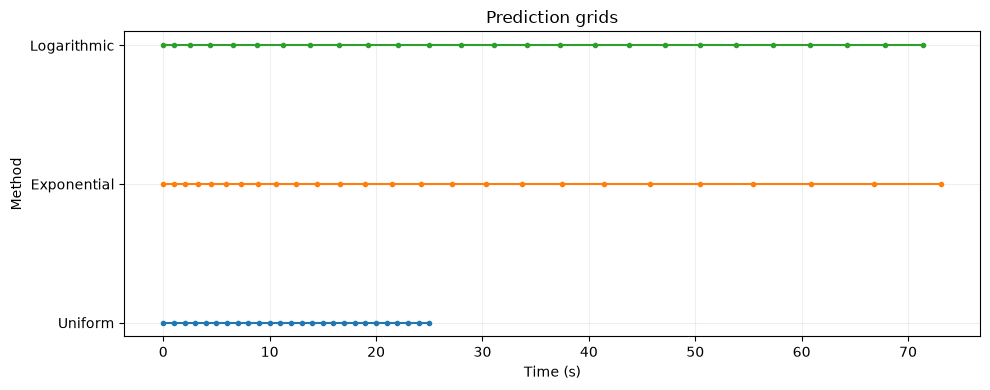

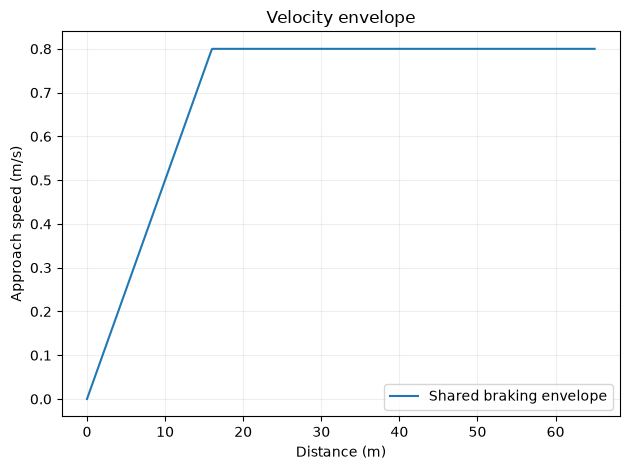

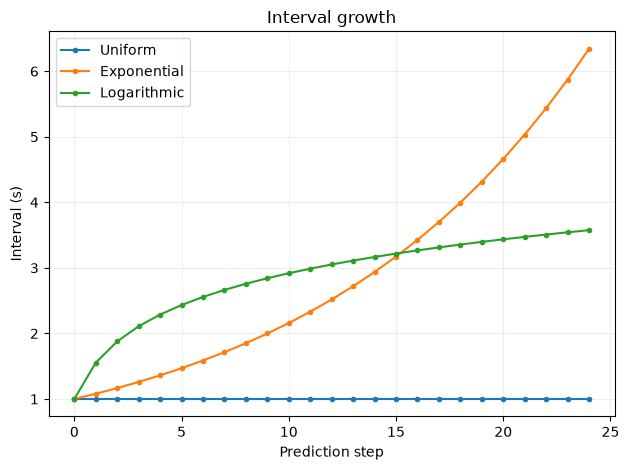

In [13]:
def finish(title,xlabel,ylabel):
    plt.title(title); plt.xlabel(xlabel); plt.ylabel(ylabel); plt.grid(alpha=.2); plt.tight_layout()
    plt.savefig(out/(title.replace(' ','_')+'.png'),dpi=150)
    if show: plt.show()
    plt.close()
plt.figure(figsize=(10,4))
for i,c in enumerate(cases):
    nodes=np.r_[0,np.cumsum(c.dt)]; plt.plot(nodes,np.full(len(nodes),i),'o-',ms=3)
plt.yticks(range(len(names)),names); finish('Prediction grids','Time (s)','Method')
d=np.linspace(0,65,500); plt.figure(); plt.plot(d,np.minimum(ALPHA*d,A_BRAKE/ALPHA),label='Shared braking envelope'); plt.legend(); finish('Velocity envelope','Distance (m)','Approach speed (m/s)')
plt.figure()
for c in cases: plt.plot(np.arange(N),c.dt, marker="o",ms=3,label=c.name)
plt.legend(); finish("Interval growth","Prediction step","Interval (s)")

## 13. 성공률, 수치적 안정성 및 분포
Wilson 구간과 성공률, ADMM 실패율, 조건수, 계산 시간 및 제약 위반량을 비교한다. 실패한 궤적의 최종 오차도 기록한다.

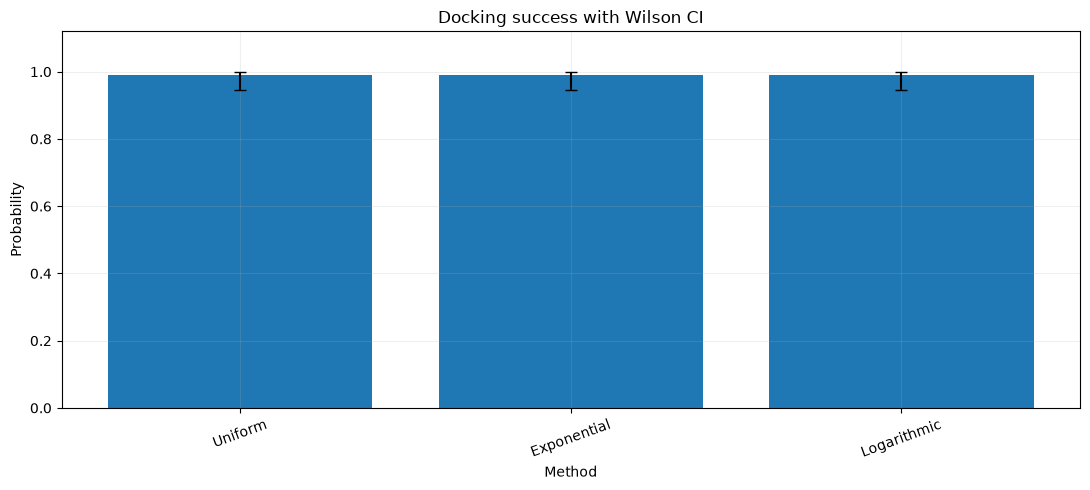

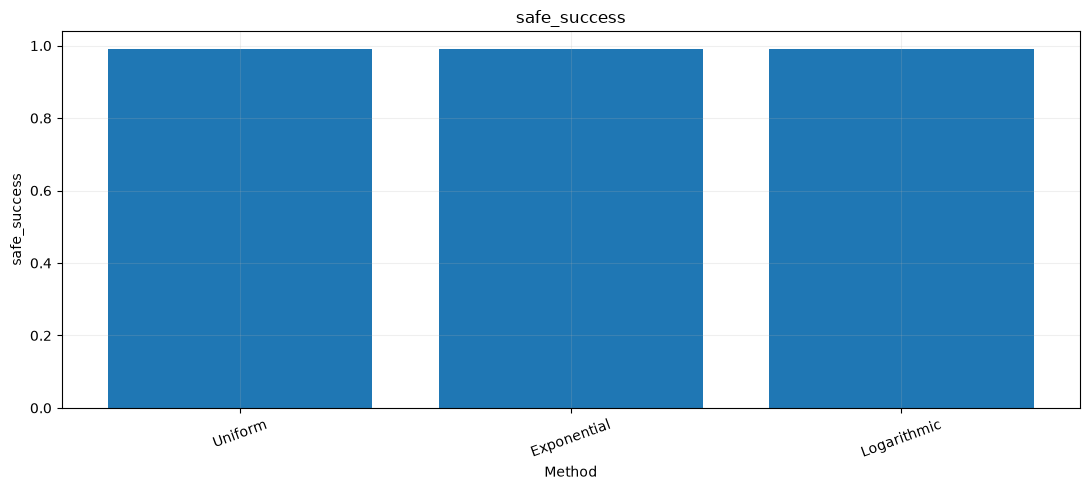

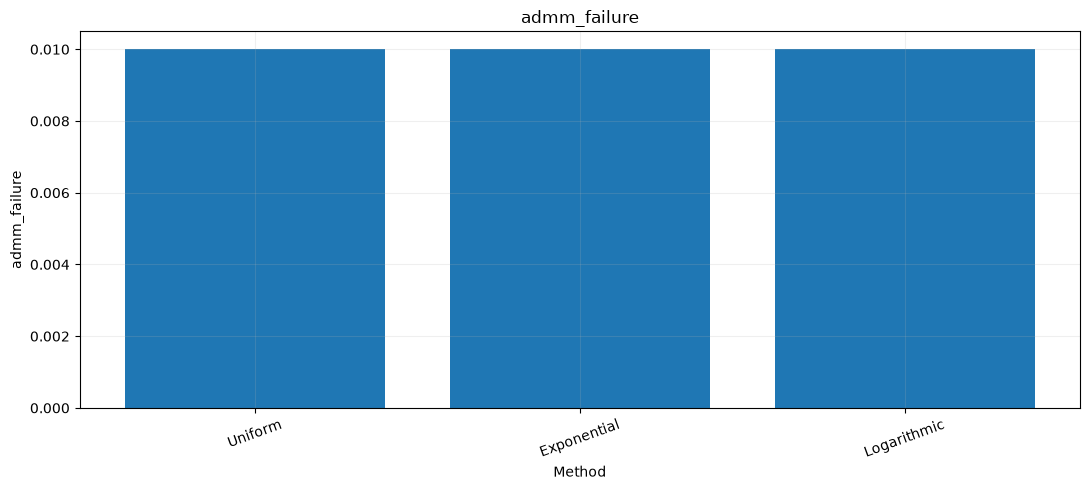

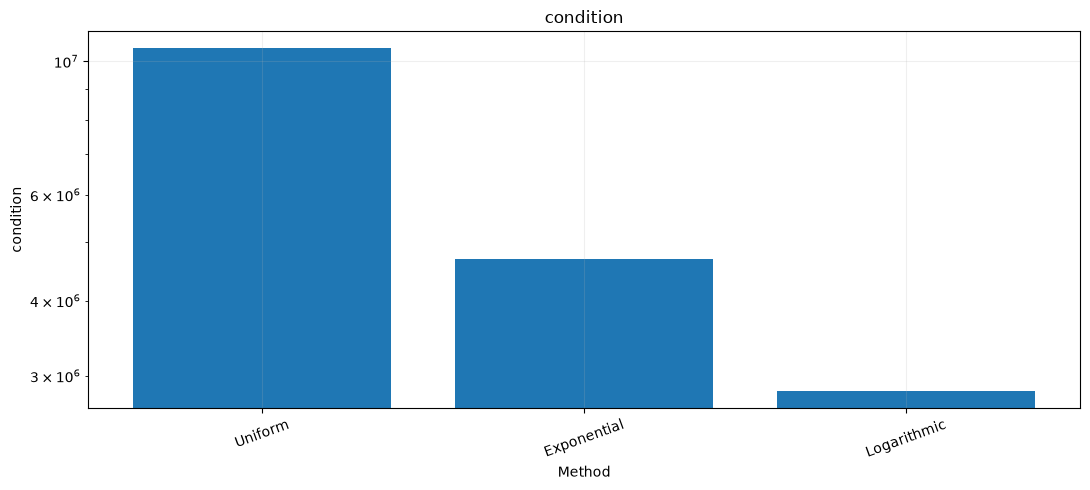

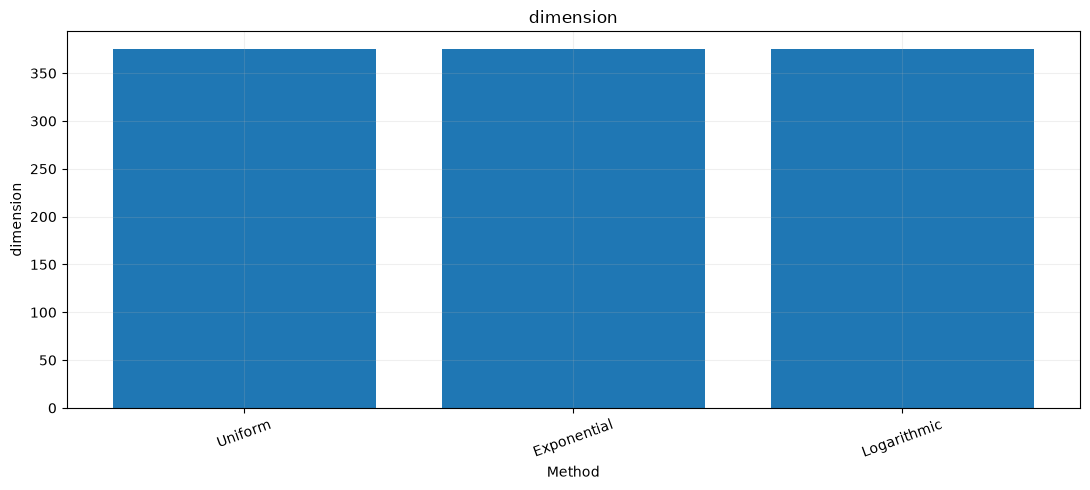

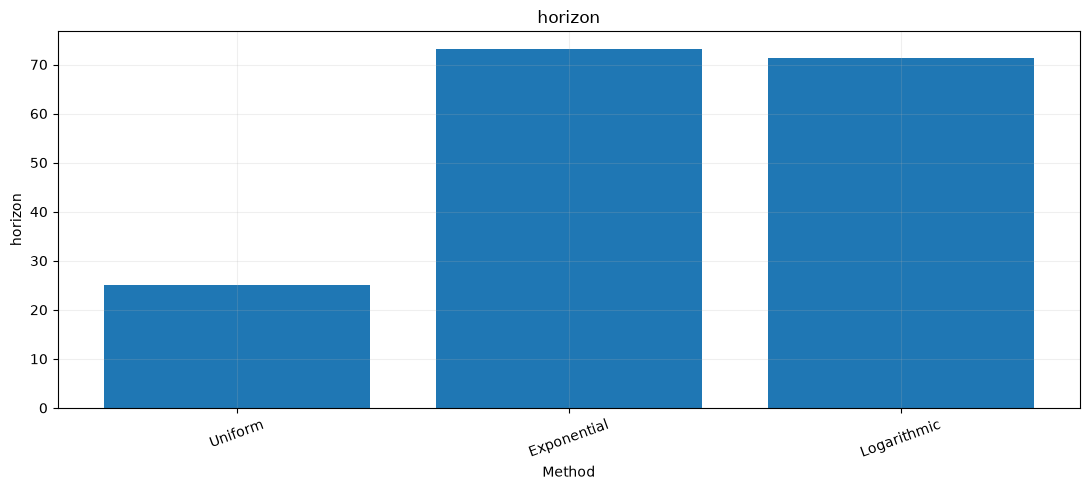

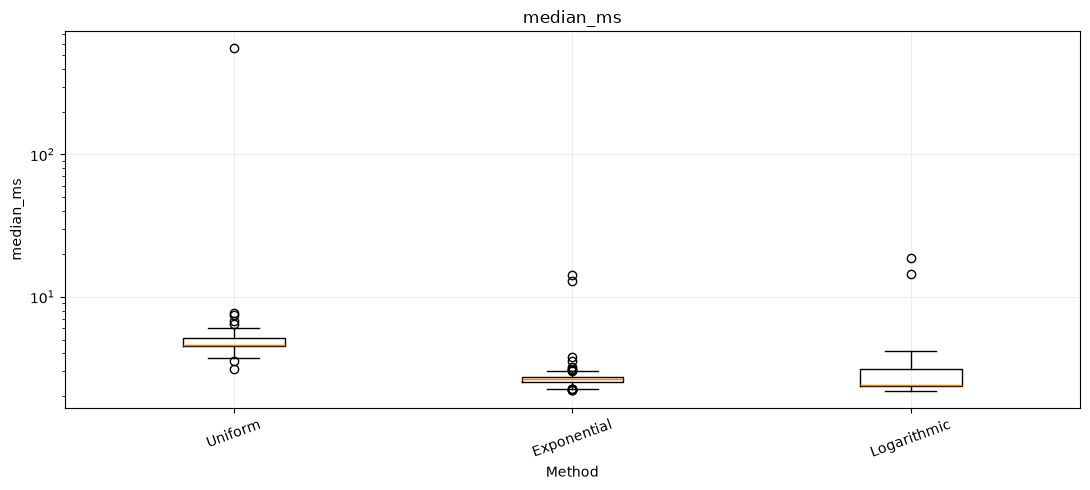

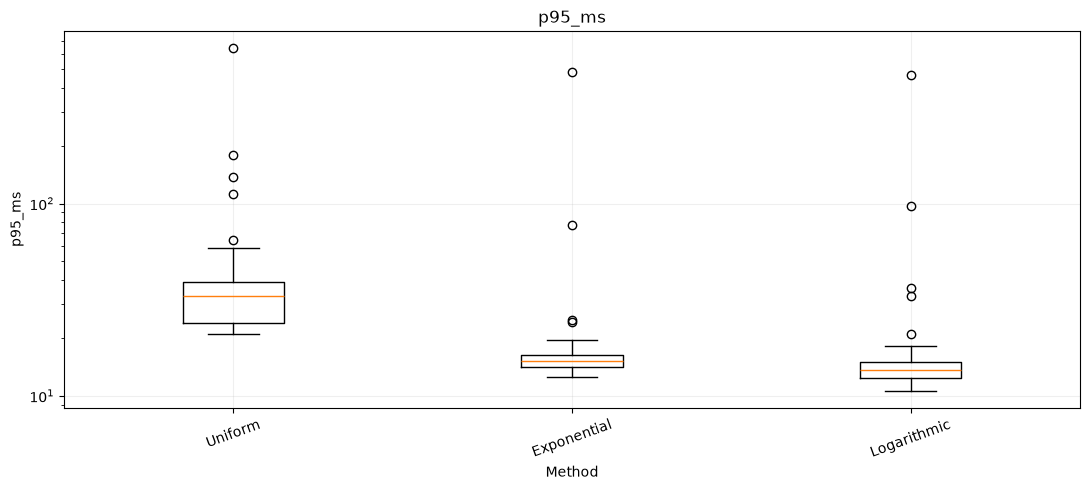

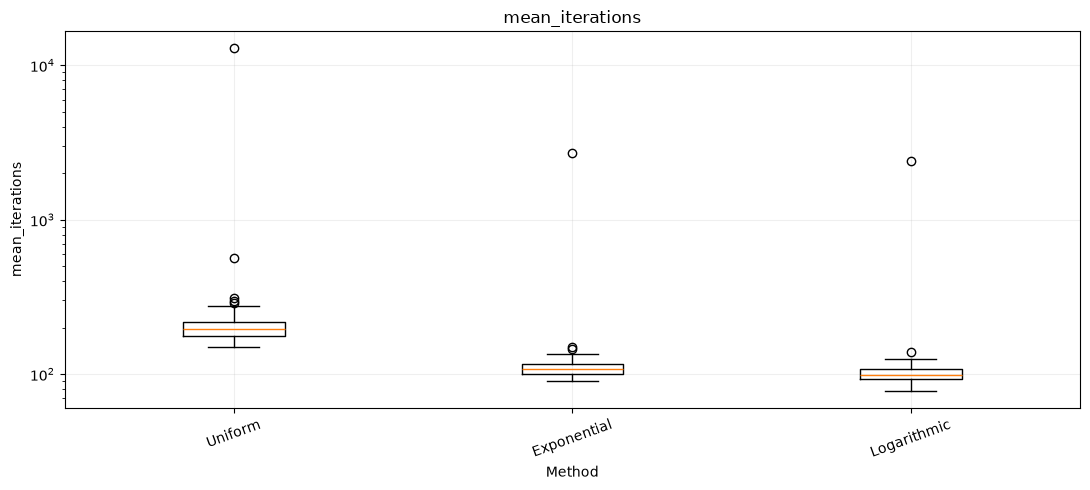

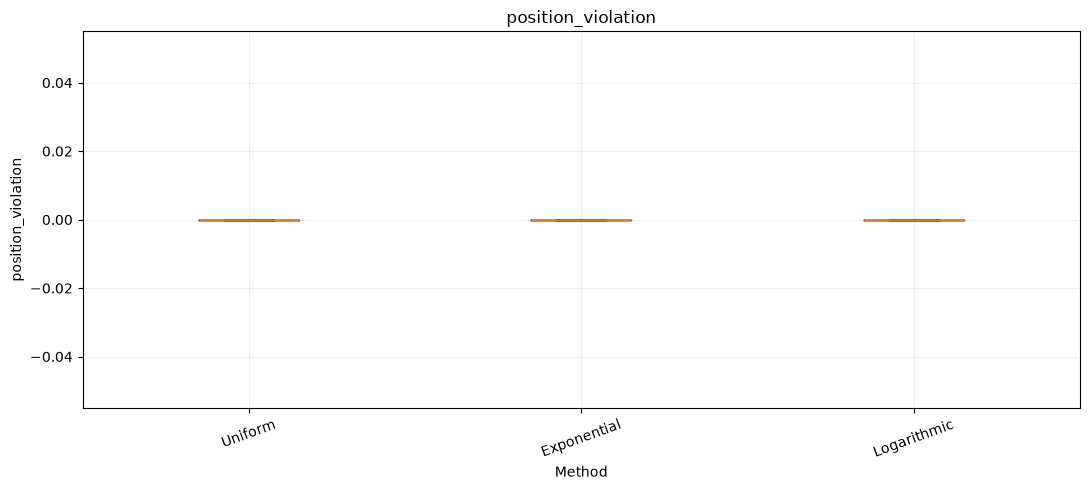

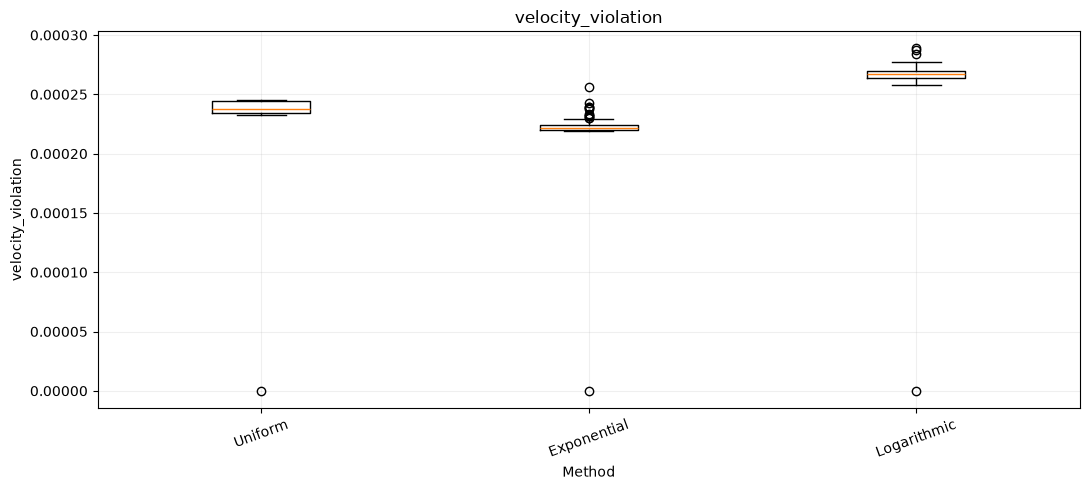

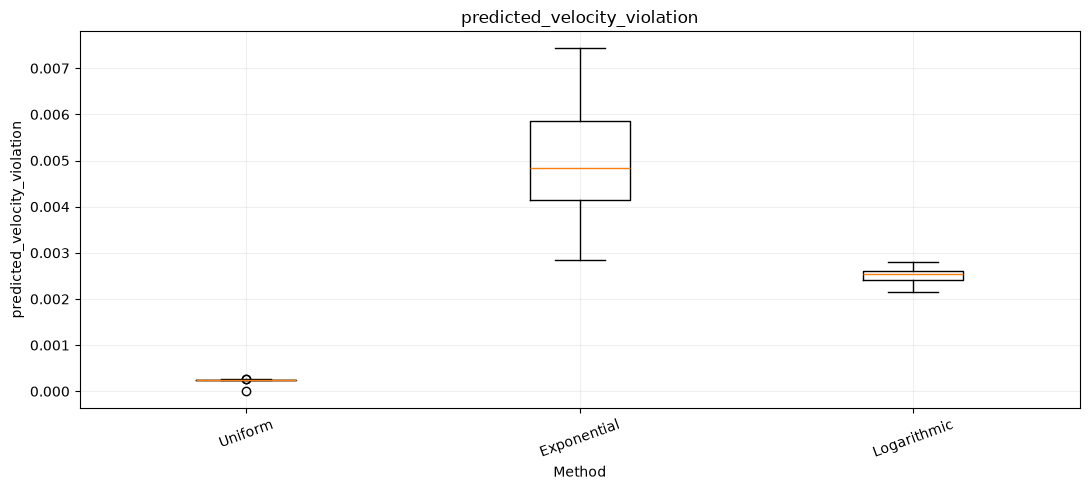

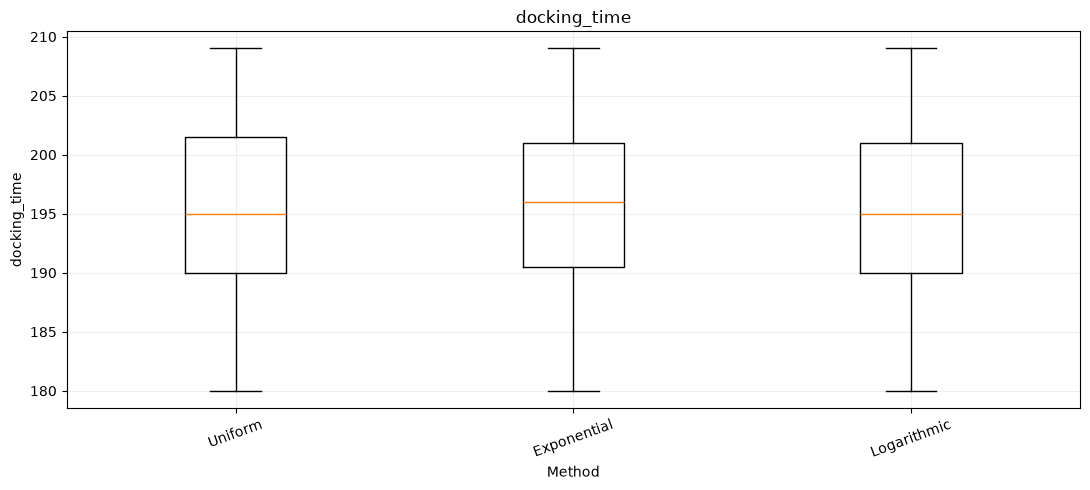

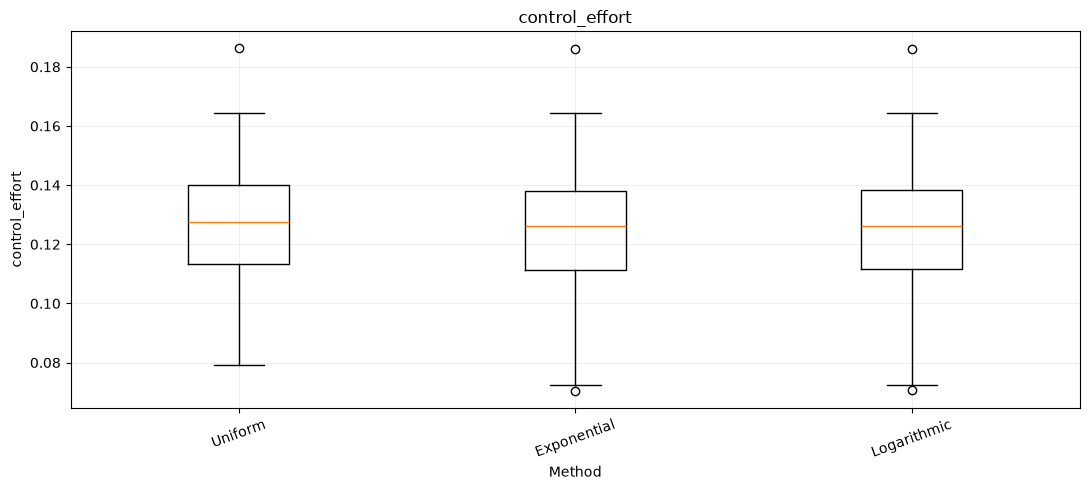

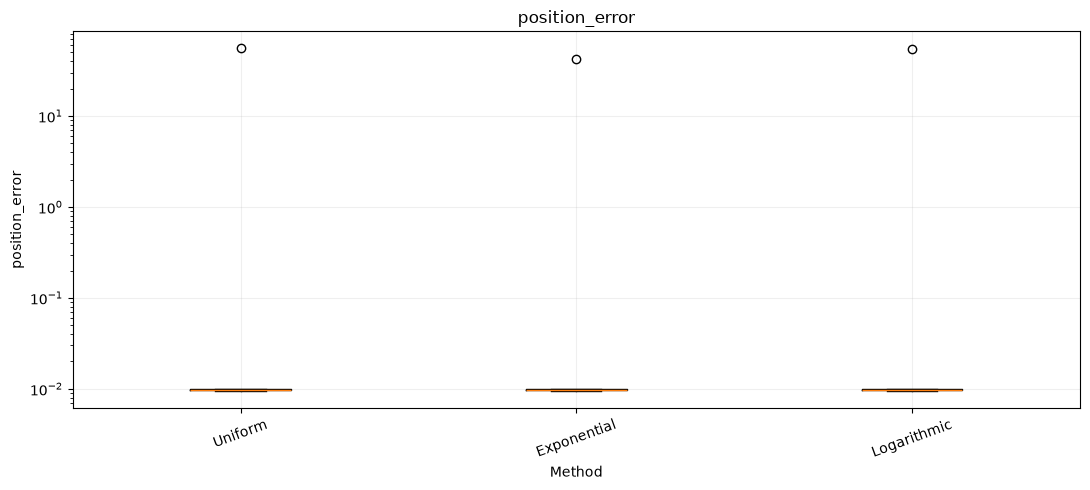

In [14]:
plt.figure(figsize=(11,5)); p=summary.success.to_numpy(); plt.bar(names,p,yerr=np.maximum(0,np.vstack([p-summary.ci_low,summary.ci_high-p])),capsize=4); plt.xticks(rotation=20); plt.ylim(0,1.12); finish('Docking success with Wilson CI','Method','Probability')
for metric in ['safe_success','admm_failure','condition','dimension','horizon']:
    plt.figure(figsize=(11,5)); plt.bar(names,summary[metric]); plt.xticks(rotation=20)
    if metric=='condition': plt.yscale('log')
    finish(metric,'Method',metric)
for metric in ['median_ms','p95_ms','mean_iterations','position_violation','velocity_violation','predicted_velocity_violation','docking_time','control_effort','position_error']:
    plt.figure(figsize=(11,5)); groups=[df.loc[(df.method==n)&(df.success if metric in ['docking_time','control_effort'] else True),metric].dropna().to_numpy() for n in names]
    plt.boxplot([v if len(v) else [np.nan] for v in groups]); plt.xticks(range(1,len(names)+1),names,rotation=20)
    if metric in ['median_ms','p95_ms','mean_iterations','position_error']: plt.yscale('log')
    finish(metric,'Method',metric)

## 14. 3차원 궤적
실선은 성공, 점선과 끝점 x 표시는 실패를 뜻한다. 포트 기준 좌표를 사용한다.

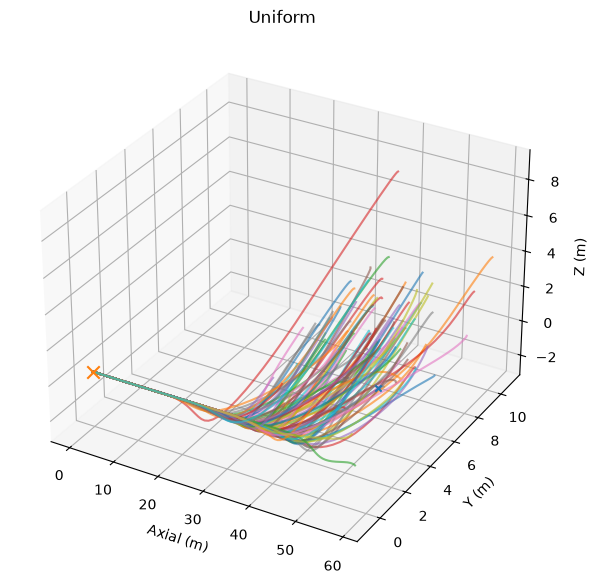

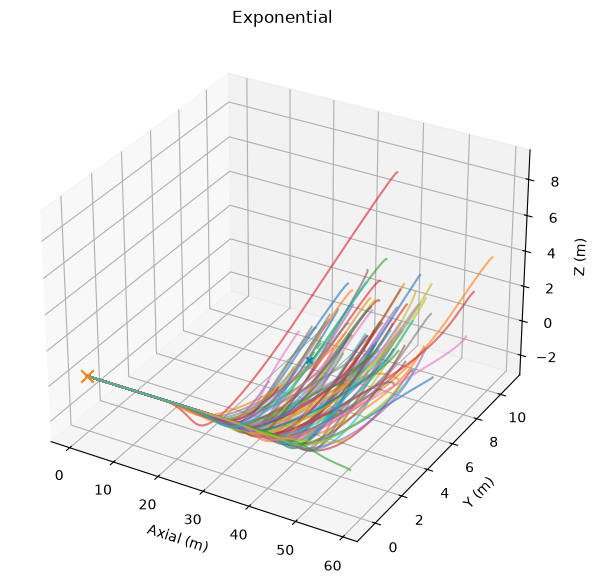

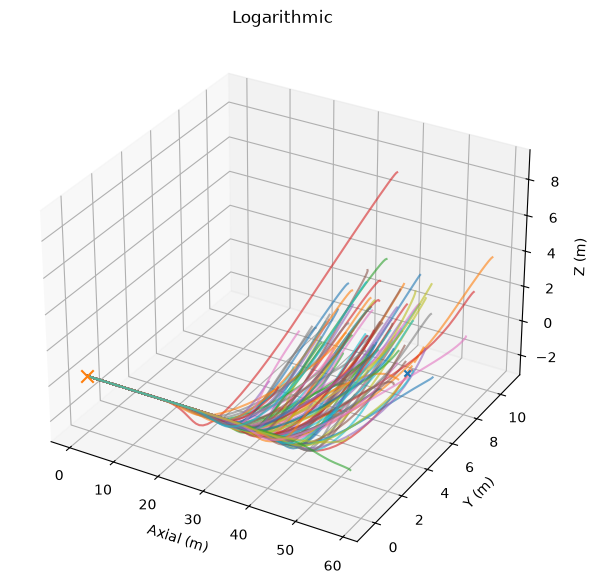

In [15]:
for name in names:
    fig=plt.figure(figsize=(8,6)); ax=fig.add_subplot(projection='3d')
    for r in results[name]:
        p=r['states'][:,:3]-PORT; ax.plot(*p.T,ls='-' if r['success'] else '--',alpha=.6)
        if not r['success']: ax.scatter(*p[-1],marker='x')
    ax.scatter(0,0,0,marker='x',s=80); ax.set(xlabel='Axial (m)',ylabel='Y (m)',zlabel='Z (m)',title=name)
    fig.tight_layout(); fig.savefig(out/(name.replace(' ','_')+'.png'),dpi=150)
    if show: plt.show()
    plt.close(fig)

## 15. 실패 원인 및 실시간 연산 분석
실패한 마지막 QP의 residual과 축 방향 거리별 ADMM 반복 횟수를 확인한다. 계산시간 경험적 CDF는 $F(t)=M^{-1}\sum_i I(t_i\le t)$ 형태로 전체 solve 표본을 집계한다. 마지막 산점도는 안전 성공률과 계산 비용의 관계를 나타낸다.

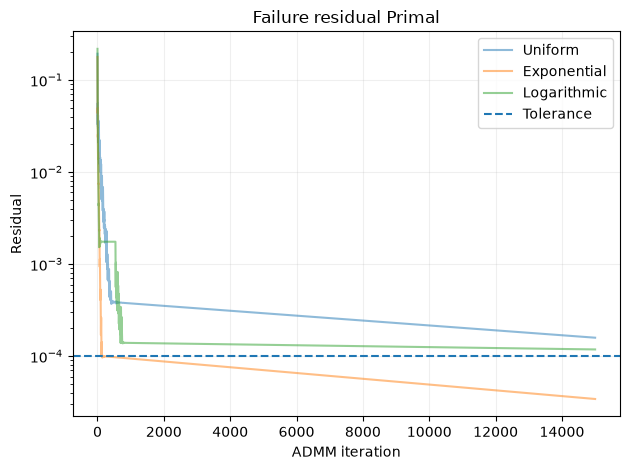

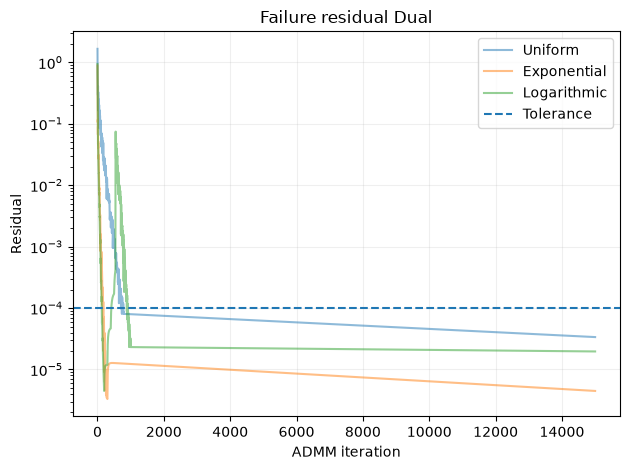

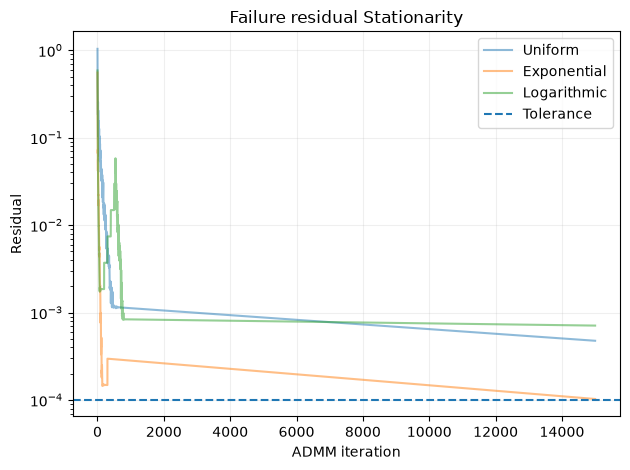

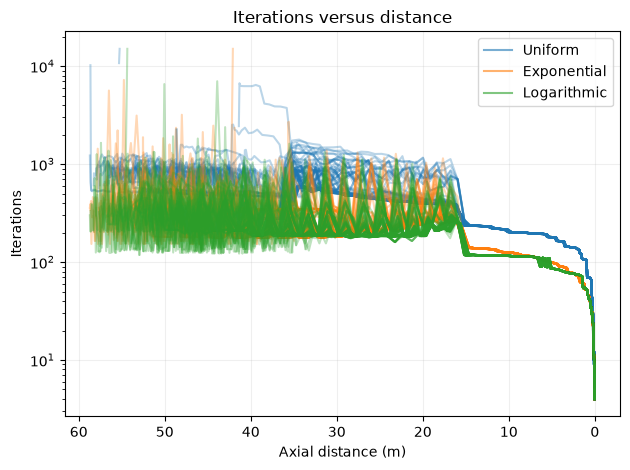

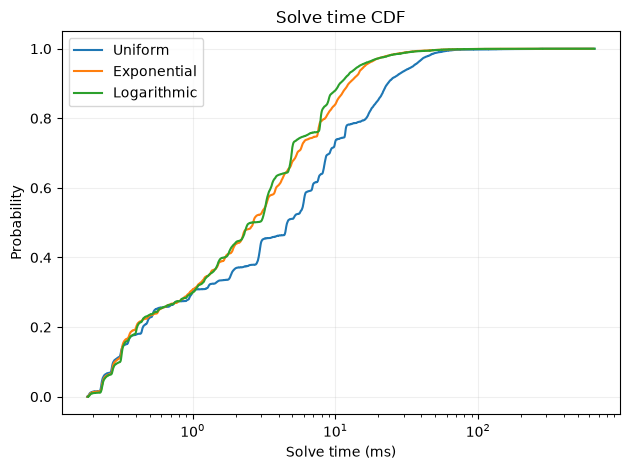

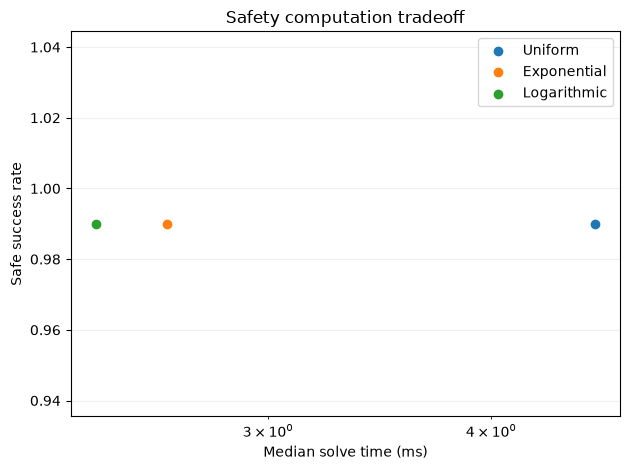

In [16]:
for key,col in [('Primal',0),('Dual',1),('Stationarity',2)]:
    plt.figure()
    for name in names:
        for i,r in enumerate(results[name]):
            if r['status']=='ADMM not converged': plt.semilogy(np.maximum(r['last_hist'][:,col],1e-15),alpha=.5,label=name if i==next(j for j,v in enumerate(results[name]) if v['status']=='ADMM not converged') else None)
    plt.axhline(1e-4,ls='--',label='Tolerance'); plt.legend(); finish('Failure residual '+key,'ADMM iteration','Residual')
plt.figure()
for name in names:
    line=None
    for r in results[name]:
        dist=r['states'][:len(r['iters']),0]-PORT[0]; length=min(len(dist),len(r['iters']))
        if line is None: line,=plt.plot(dist[:length],r['iters'][:length],alpha=.6,label=name)
        else: plt.plot(dist[:length],r['iters'][:length],alpha=.3,color=line.get_color())
plt.gca().invert_xaxis(); plt.yscale('log'); plt.legend(); finish('Iterations versus distance','Axial distance (m)','Iterations')
plt.figure()
for name in names:
    values=np.sort(np.concatenate([r['times']*1000 for r in results[name]])); plt.step(values,np.arange(1,len(values)+1)/len(values),label=name)
plt.xscale('log'); plt.legend(); finish('Solve time CDF','Solve time (ms)','Probability')
plt.figure()
for row in summary.itertuples(): plt.scatter(row.median_ms,row.safe_success,label=row.method)
plt.xscale('log'); plt.legend(); finish('Safety computation tradeoff','Median solve time (ms)','Safe success rate')
if show: plt.show()

## 16. 기본 결과 해석
실험 A에서는 예측 범위와 격자 분포가 함께 달라진다. 실험 B에서는 두 비균일 격자의 전체 범위를 통제한다. KKT 차원은 같지만 반복 횟수와 계산시간은 달라질 수 있다. LP feasibility와 ADMM 수렴 실패를 구분한다. 안전성은 유한 시간 표본에서의 검사이며 연속시간 보장이 아니다.

## 17. 대응 표본 통계 비교
동일 초기 상태에서 얻은 성공 여부를 대응시킨다. $b$는 기준군만 성공, $c$는 비교군만 성공한 표본 수이다. 귀무가설 아래 $b\mid(b+c)\sim\mathrm{Binomial}(b+c,1/2)$이므로 정확 McNemar 검정을 사용한다. 연산시간은 두 모델 모두 성공한 표본에서 $S_i=t_{U,i}/t_{m,i}$를 계산하고 대응 bootstrap으로 중앙값의 95% 구간을 추정한다. 두 비교의 p-value는 탐색적이며 다중검정 보정 전이다.

     method  uniform_only  method_only  mcnemar_p  both_safe  speedup  speedup_low  speedup_high  effort_difference  docking_time_difference
Exponential             1            1        1.0         98 1.796421     1.761214      1.867027          -0.002648                -0.132653
Logarithmic             1            1        1.0         98 1.893098     1.841150      1.905248          -0.002426                -0.112245


/var/folders/2p/hhtqy8b96_d6zjxc3jlbxhz80000gn/T/ipykernel_39761/1229152376.py:6: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  pair=base.join(df[df.method==name].set_index('trial'),lsuffix='_u',rsuffix='_m',validate='one_to_one')
/var/folders/2p/hhtqy8b96_d6zjxc3jlbxhz80000gn/T/ipykernel_39761/1229152376.py:6: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  pair=base.join(df[df.method==name].set_index('trial'),lsuffix='_u',rsuffix='_m',validate='one_to_one')


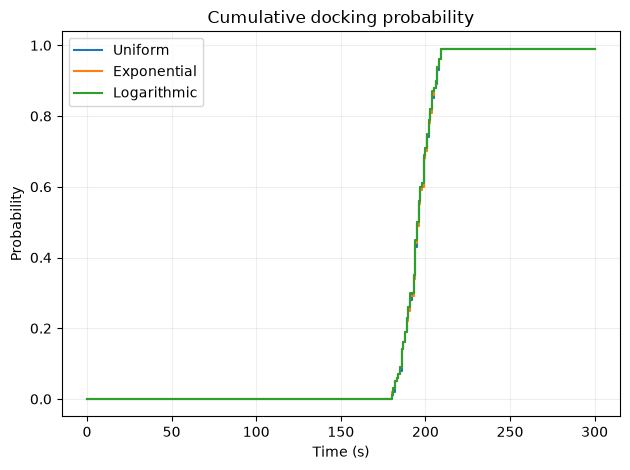

In [17]:
from scipy.stats import binomtest
base = df[df.method=='Uniform'].set_index('trial')
paired_rows=[]
boot_rng=np.random.default_rng(SEED+11)
for name in names[1:]:
    pair=base.join(df[df.method==name].set_index('trial'),lsuffix='_u',rsuffix='_m',validate='one_to_one')
    b=int((pair.safe_success_u & ~pair.safe_success_m).sum())
    c=int((~pair.safe_success_u & pair.safe_success_m).sum())
    both=pair[pair.safe_success_u & pair.safe_success_m]
    speed=(both.median_ms_u/both.median_ms_m).to_numpy()
    ci=np.percentile(np.median(boot_rng.choice(speed,(2000,len(speed)),replace=True),axis=1),[2.5,97.5]) if len(speed) else [np.nan,np.nan]
    paired_rows.append(dict(method=name,uniform_only=b,method_only=c,mcnemar_p=binomtest(b,b+c,.5).pvalue if b+c else 1.,both_safe=len(both),speedup=np.median(speed) if len(speed) else np.nan,speedup_low=ci[0],speedup_high=ci[1],effort_difference=(both.control_effort_m-both.control_effort_u).mean(),docking_time_difference=(both.docking_time_m-both.docking_time_u).mean()))
paired_df=pd.DataFrame(paired_rows)
paired_df.to_csv(out/'paired.csv',index=False)
print(paired_df.to_string(index=False))
plt.figure()
for name in names:
    g=df[df.method==name]; t=np.arange(0,duration+DT,DT)
    plt.step(t,[np.mean(g.docking_time<=v) for v in t],where='post',label=name)
plt.legend(); finish('Cumulative docking probability','Time (s)','Probability')

## 18. 추가 실험 설계
- Point sweep: $N$을 줄여 최소 성공 가능 문제 규모 $15N$을 확인한다.
- Iteration sweep: $J_{\max}$를 제한한다. 수렴하지 않으면 기존 정책과 동일하게 종료한다(실제 비상 제어 정책은 모델링하지 않는다).
- Uncertainty sweep: 초기 표준편차를 $q\sigma$로 변경한다. 초기 제약을 만족하는 표본만 사용하며 채택률도 기록한다.
- Matched horizon: 두 비균일 격자의 $T$를 일치시킨다.
- Growth sweep: Exponential의 $\gamma$와 이에 맞춘 Logarithmic의 $\beta$를 변경한다.
- 2D sweep: $N\times J_{\max}$를 함께 변경한다(기본 비활성화).

각 설정에서 동일한 표본을 세 모델에 사용한다. 기본 100회 실험과 별도로 `SWEEP_TRIALS`를 조절한다. 초기 조건만 변화시키므로 외란이나 센서 오차에 대한 강건성 보장은 아니다. 시간 제한은 모든 설정에서 동일하다. Quick 모드는 각 설정 1회/5초로 동작만 확인한다.

In [18]:
def sample_states(count, scale=1.):
    gen=np.random.default_rng(SEED)
    accepted=[]; attempts=0
    while len(accepted)<count:
        attempts+=1
        if attempts>100000: raise RuntimeError('Sampling limit reached')
        x=gen.normal(INITIAL,INITIAL_STD*scale)
        if np.all(C@(x-REF)<=0) and -x[3]<=A_BRAKE/ALPHA: accepted.append(x)
    return np.asarray(accepted),count/attempts

def run_setting(label, points=N, budget=MAX_ITER, uncertainty=1., mode='A', gamma=GAMMA):
    count=1 if QUICK else SWEEP_TRIALS
    samples_,accept=sample_states(count,uncertainty)
    configs=[Case(name,grid(points,kind,mode=mode,gamma=gamma)) for name,kind in [('Uniform','uniform'),('Exponential','exponential'),('Logarithmic','logarithmic')]]
    rng_order=np.random.default_rng(SEED+1)
    rows=[]
    cond={c.name:np.linalg.cond(Solver(c).KKT.toarray()) for c in configs}
    for i,x in enumerate(samples_):
        for j in rng_order.permutation(len(configs)):
            c=configs[j]; r=simulate(c,duration,budget,x,verbose=False)
            pos=np.max(r['actual'][:,:2]) if len(r['actual']) else np.nan
            vel=np.max(r['actual'][:,2:]) if len(r['actual']) else np.nan
            rows.append(dict(experiment=label,method=c.name,N=points,budget=budget,uncertainty=uncertainty,mode=mode,gamma=gamma,trial=i,acceptance=accept,horizon=c.dt.sum(),dimension=15*points,condition=cond[c.name],success=r['success'],safe_success=bool(r['success'] and pos<=SAFE_POS_TOL and vel<=SAFE_VEL_TOL),status=r['status'],feasibility=r['feasibility'],median_ms=1000*np.median(r['times']),p95_ms=1000*np.percentile(r['times'],95),iterations=np.mean(r['iters']),max_iterations=np.max(r['iters']),docking_time=len(r['controls'])*DT if r['success'] else np.nan,effort=DT*np.sum(r['controls']**2) if r['success'] else np.nan,position_violation=pos,velocity_violation=vel,final_error=np.linalg.norm(r['states'][-1,:3]-PORT),deadline_miss=np.mean(r['times']>DT)))
    print(f'{label}: N={points}, budget={budget}, uncertainty={uncertainty}, gamma={gamma}, mode={mode}',flush=True)
    return rows

sweep_rows=[]
if RUN_SWEEPS:
    settings=[dict(label='points',points=v) for v in (N_LIST[:2] if QUICK else N_LIST)]
    settings += [dict(label='budget',budget=v) for v in (ITER_LIST[:2] if QUICK else ITER_LIST)]
    settings += [dict(label='uncertainty',uncertainty=v) for v in (UNCERTAINTY_LIST[:2] if QUICK else UNCERTAINTY_LIST)]
    if RUN_MATCHED: settings += [dict(label='matched',mode='B')]
    if RUN_GROWTH: settings += [dict(label='growth',mode='B',gamma=v) for v in (GAMMA_LIST[:2] if QUICK else GAMMA_LIST)]
    if RUN_2D: settings += [dict(label='2d',points=v,budget=b) for v in (N_LIST[:2] if QUICK else N_LIST) for b in (ITER_LIST[:2] if QUICK else ITER_LIST)]
    for setting in settings:
        sweep_rows.extend(run_setting(**setting))
        pd.DataFrame(sweep_rows).to_csv(out/'sweep_trials.csv',index=False)
sweep_df=pd.DataFrame(sweep_rows)

points: N=5, budget=15000, uncertainty=1.0, gamma=1.08, mode=A
points: N=10, budget=15000, uncertainty=1.0, gamma=1.08, mode=A
points: N=15, budget=15000, uncertainty=1.0, gamma=1.08, mode=A
points: N=20, budget=15000, uncertainty=1.0, gamma=1.08, mode=A
points: N=25, budget=15000, uncertainty=1.0, gamma=1.08, mode=A
points: N=30, budget=15000, uncertainty=1.0, gamma=1.08, mode=A
budget: N=25, budget=100, uncertainty=1.0, gamma=1.08, mode=A
budget: N=25, budget=200, uncertainty=1.0, gamma=1.08, mode=A
budget: N=25, budget=500, uncertainty=1.0, gamma=1.08, mode=A
budget: N=25, budget=1000, uncertainty=1.0, gamma=1.08, mode=A
budget: N=25, budget=3000, uncertainty=1.0, gamma=1.08, mode=A
budget: N=25, budget=15000, uncertainty=1.0, gamma=1.08, mode=A
uncertainty: N=25, budget=15000, uncertainty=0.5, gamma=1.08, mode=A
uncertainty: N=25, budget=15000, uncertainty=1.0, gamma=1.08, mode=A
uncertainty: N=25, budget=15000, uncertainty=2.0, gamma=1.08, mode=A
uncertainty: N=25, budget=15000, u

## 19. 민감도 결과와 최소 계산 예산
각 조건의 안전 성공률에 Wilson 구간을 표시한다. $N^*=\min\{N:\hat p_{safe}\ge0.95\}$ 및 $J^*=\min\{J:\hat p_{safe}\ge0.95\}$는 시험한 이산 후보에 한한 추정값이다. 신뢰구간 하한이 0.95 이상인 경우도 별도 표시한다. 적은 표본에서는 높은 관측 성공률만으로 95% 신뢰성을 확증할 수 없다.

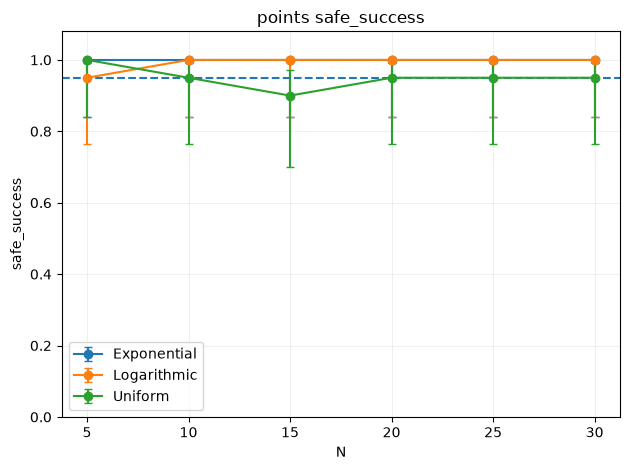

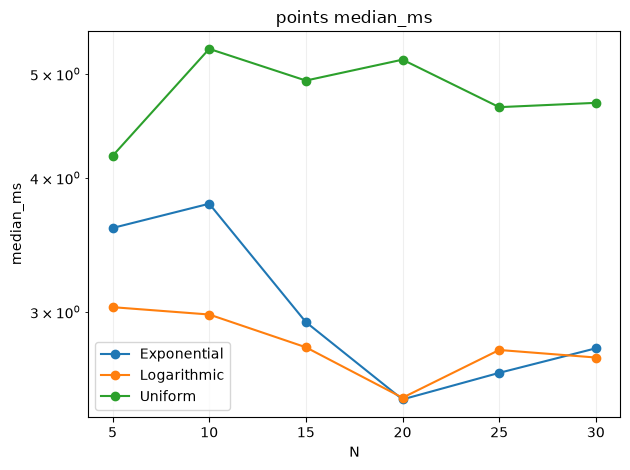

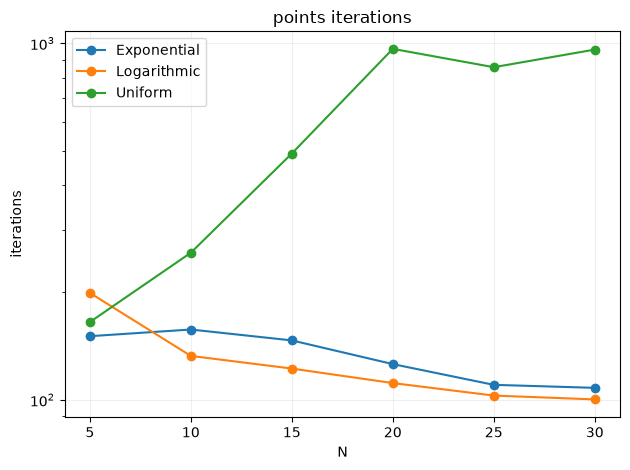

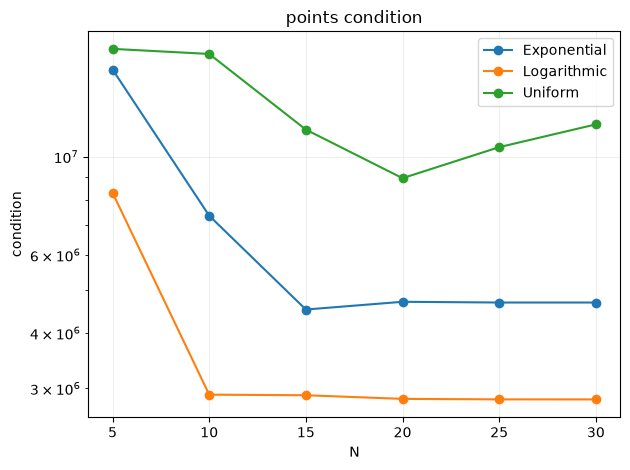

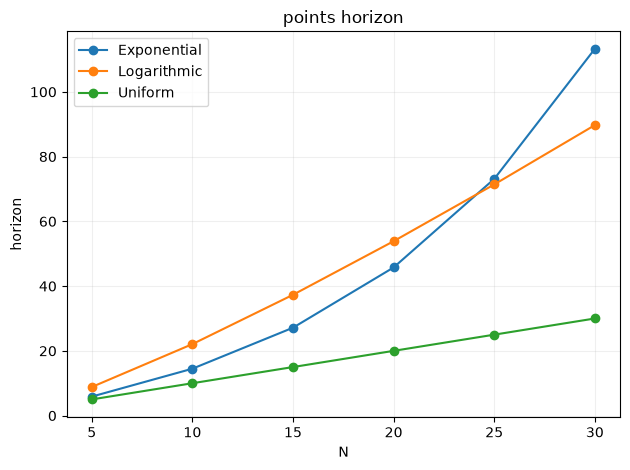

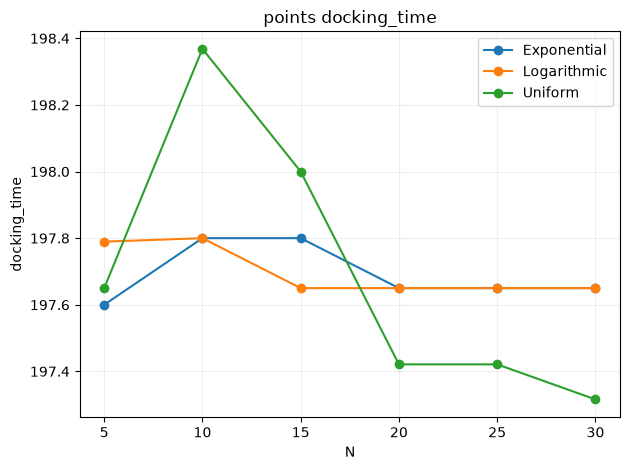

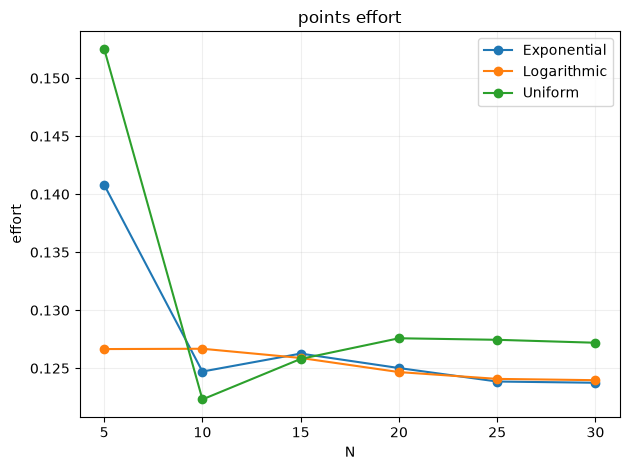

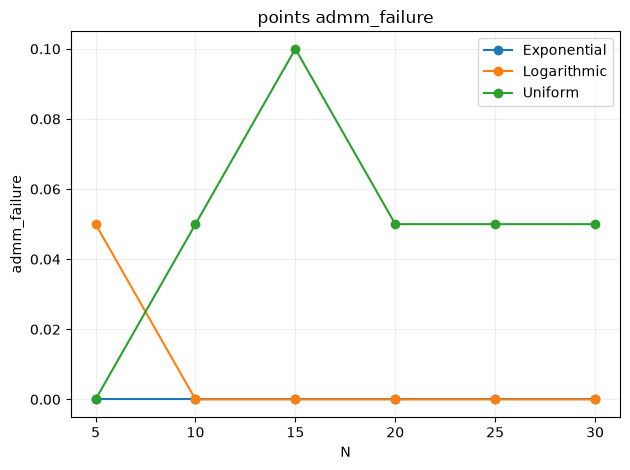

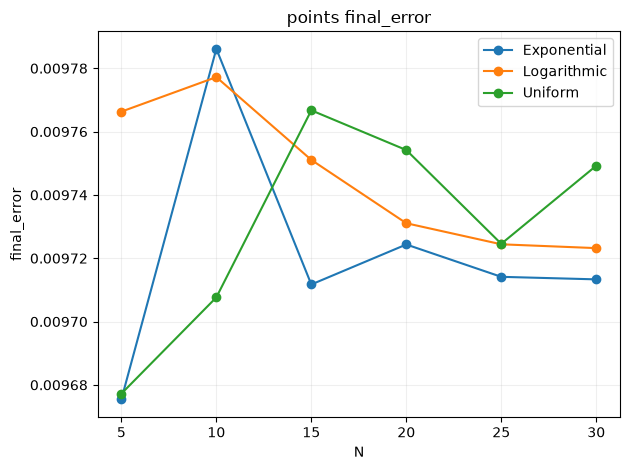

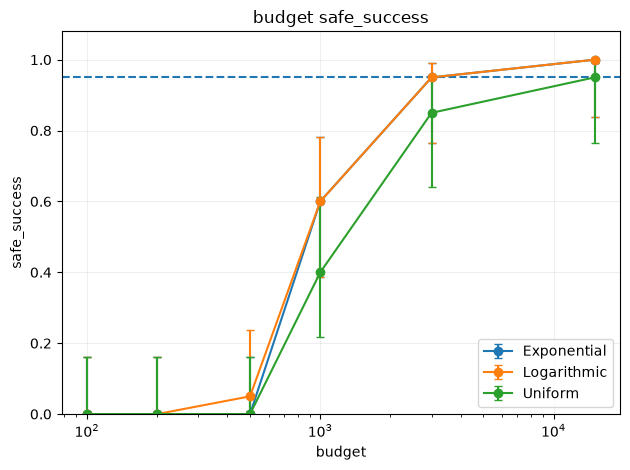

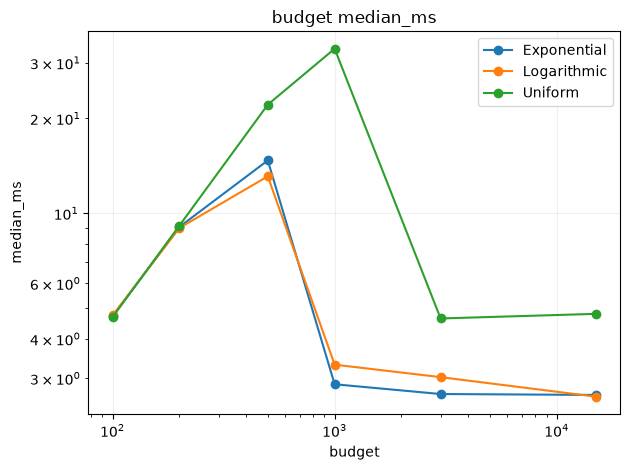

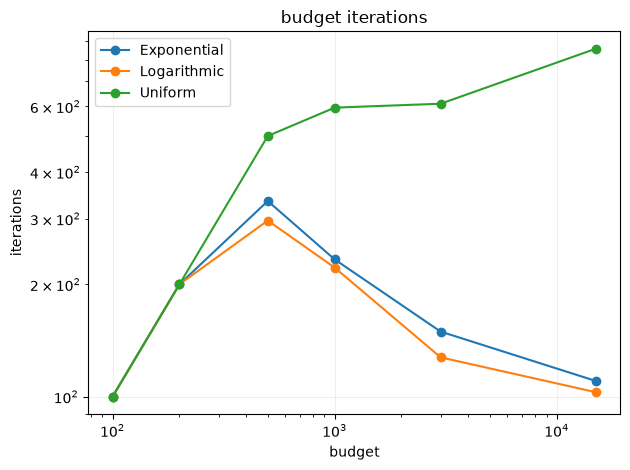

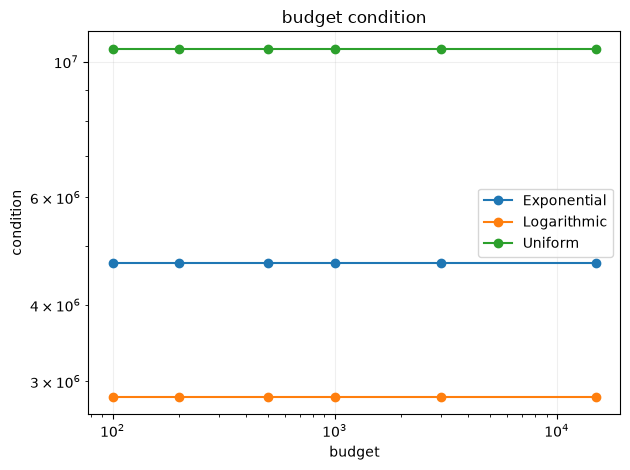

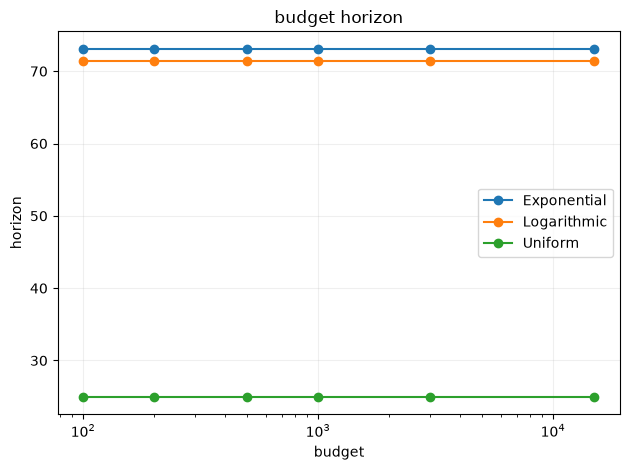

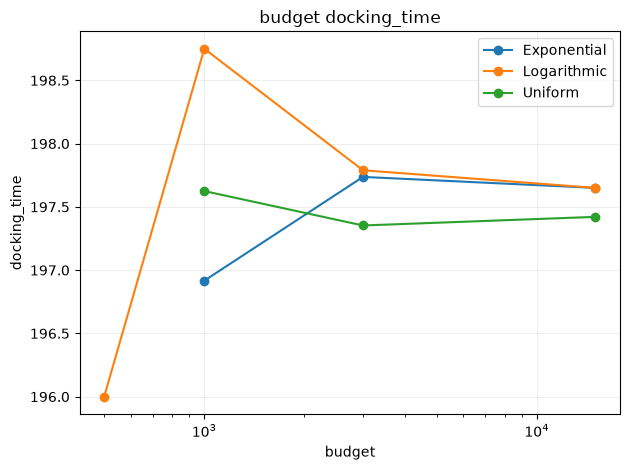

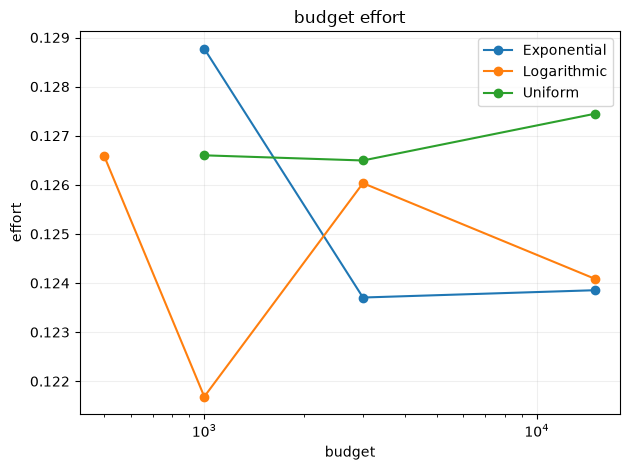

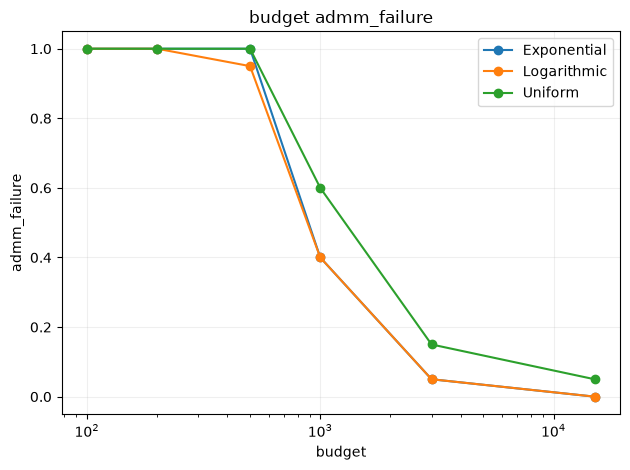

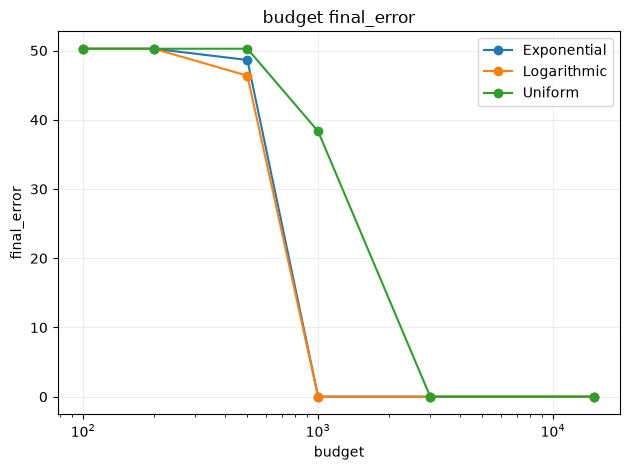

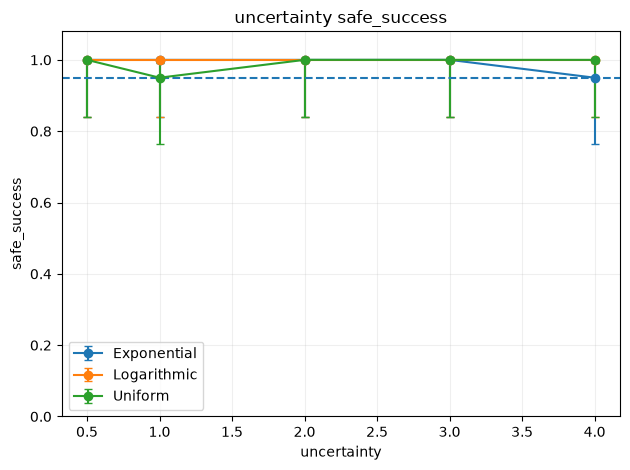

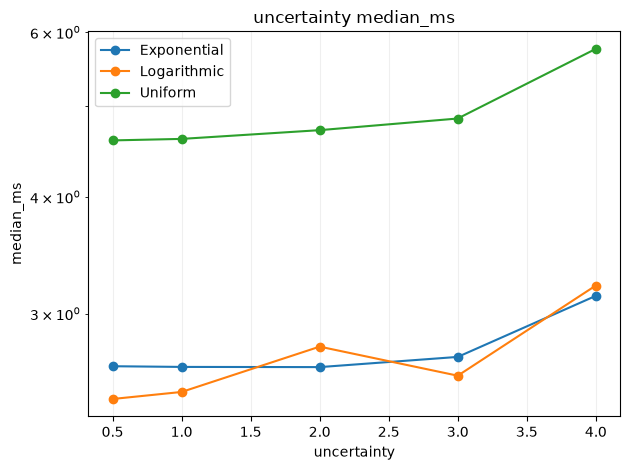

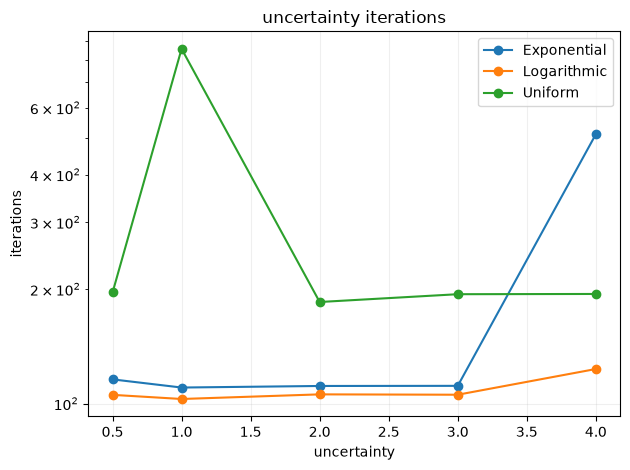

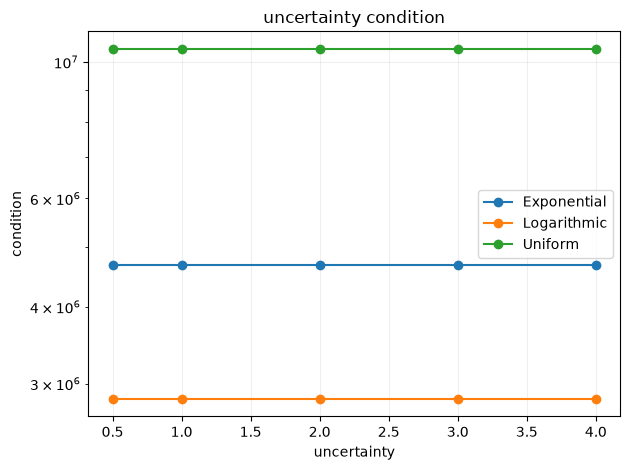

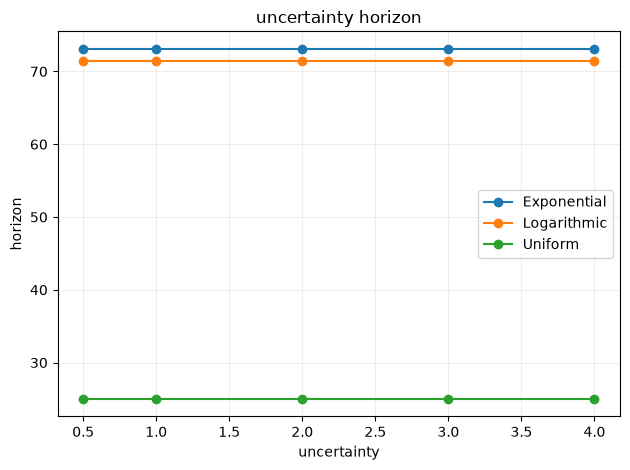

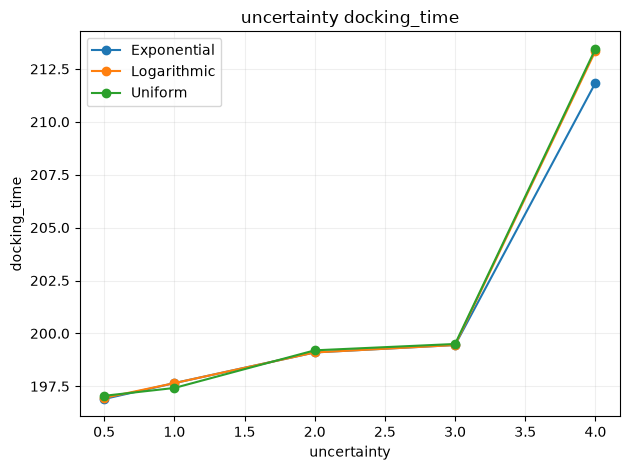

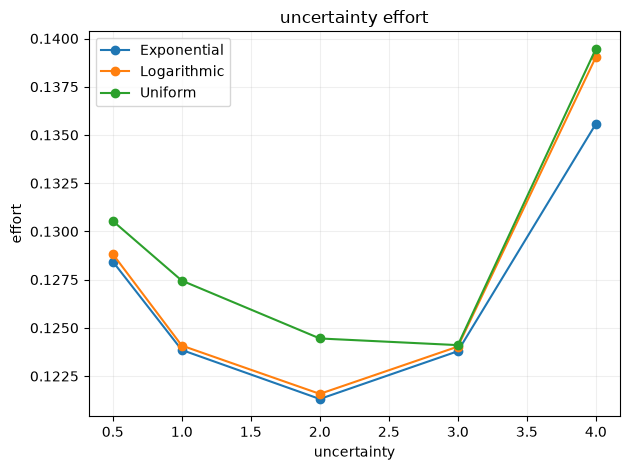

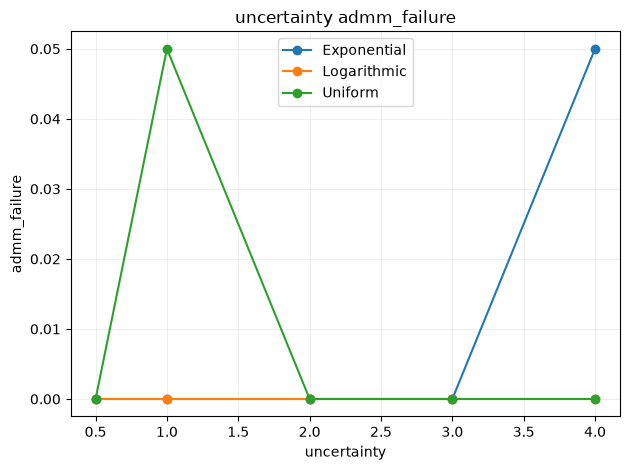

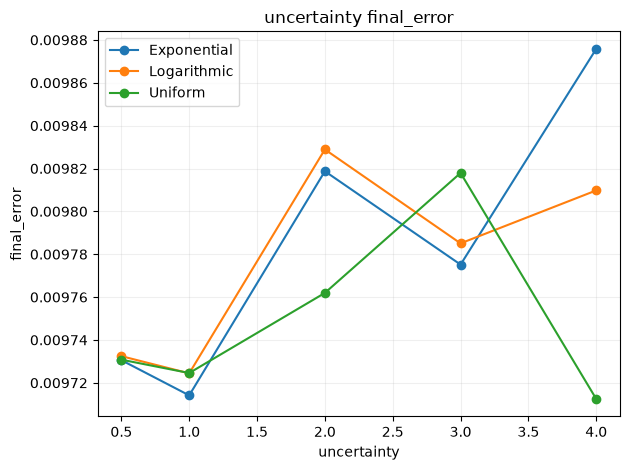

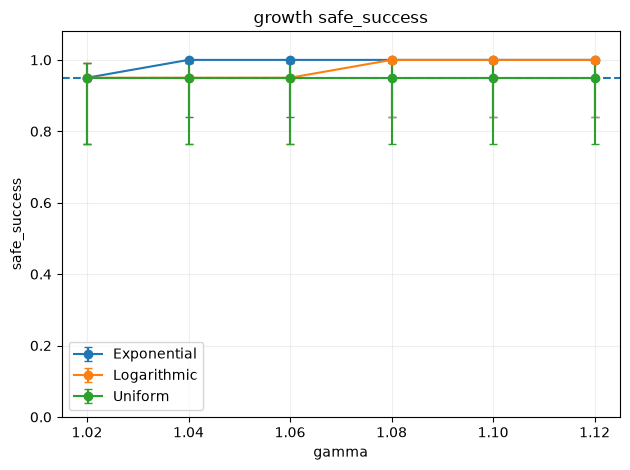

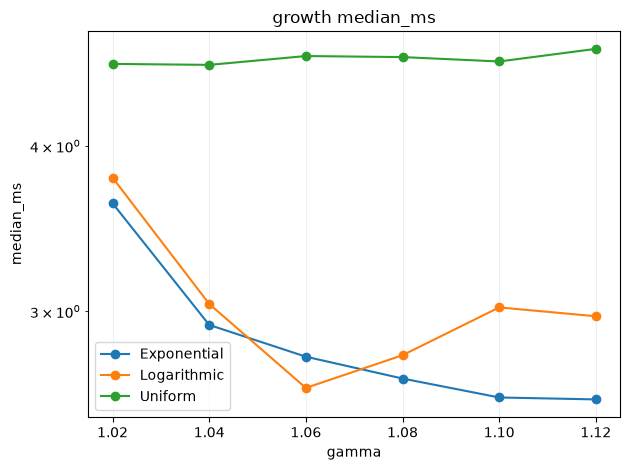

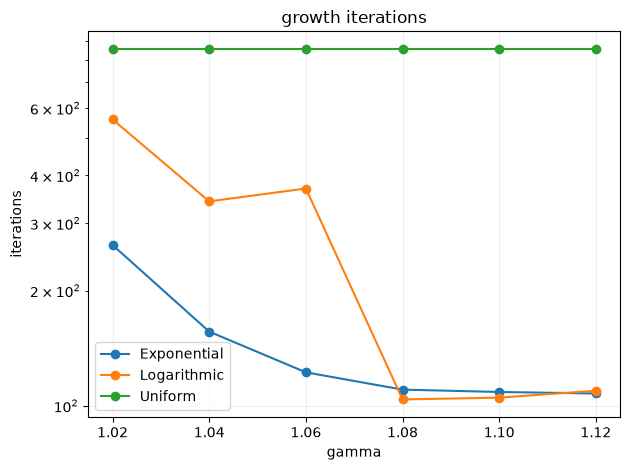

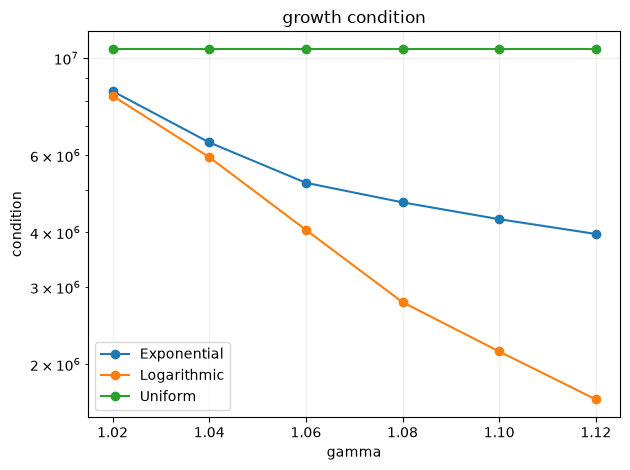

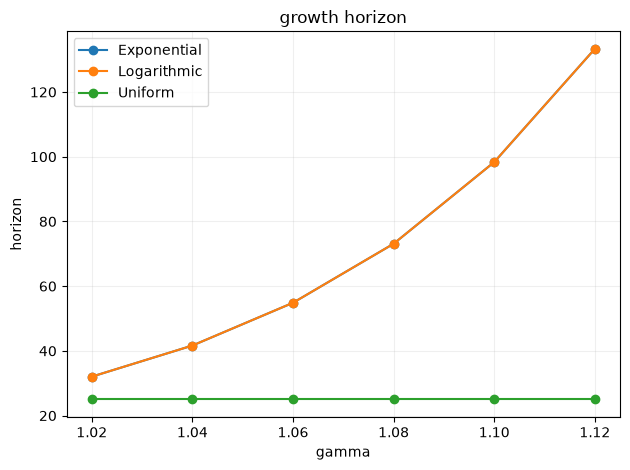

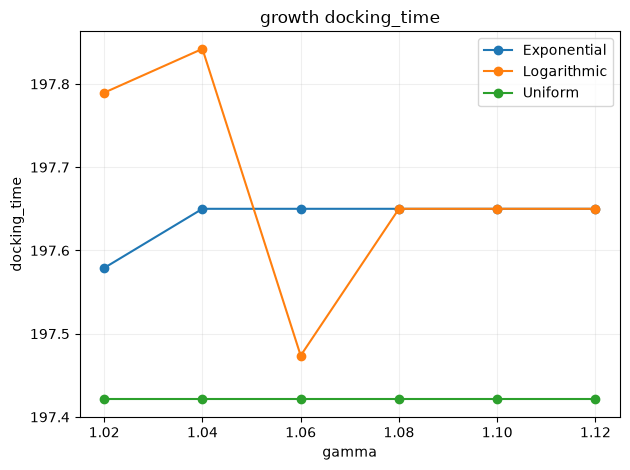

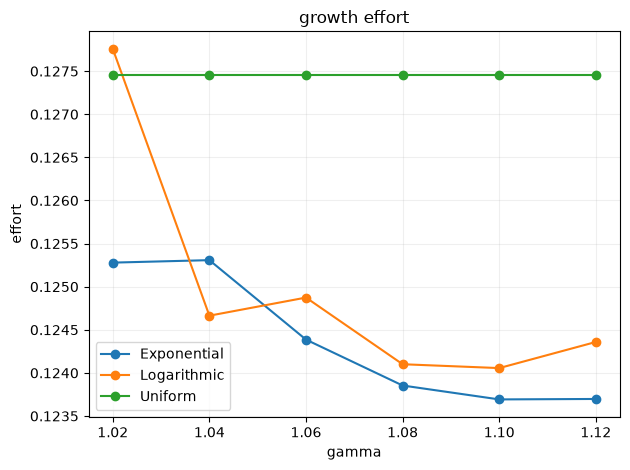

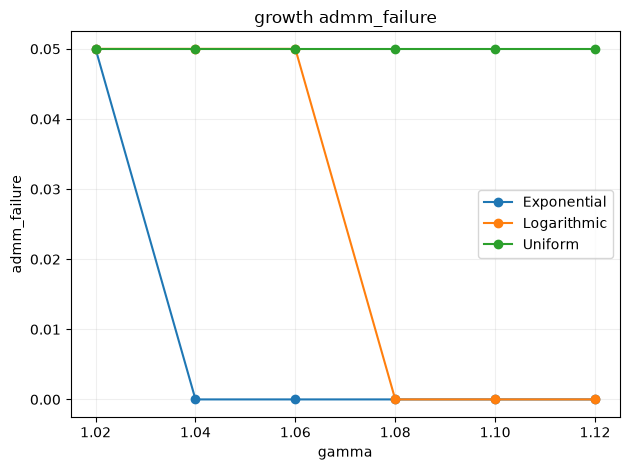

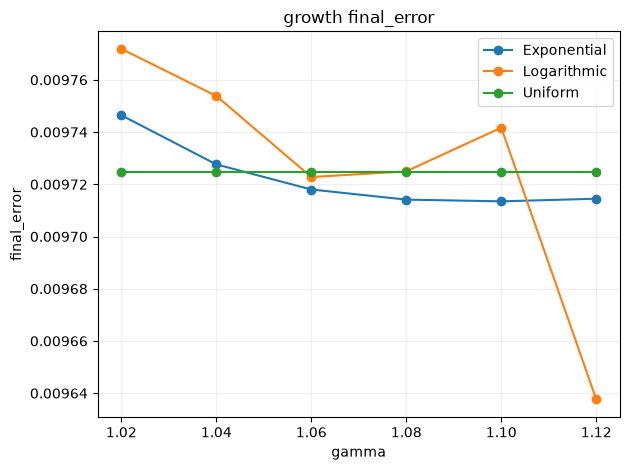

experiment      method  minimum_observed  minimum_ci_verified
    points Exponential                 5                  NaN
    points Logarithmic                 5                  NaN
    points     Uniform                 5                  NaN
    budget Exponential              3000                  NaN
    budget Logarithmic              3000                  NaN
    budget     Uniform             15000                  NaN
Matched horizon:
 experiment      method  N  budget  uncertainty mode  gamma  trials  safe_success  success  admm_failure  median_ms    p95_ms  iterations  docking_time   effort    condition  horizon  acceptance  deadline_miss  final_error  position_violation  velocity_violation   ci_low  ci_high
   matched Exponential 25   15000          1.0    B   1.08      20          1.00     1.00          0.00   2.628667 18.802002  110.164616    197.650000 0.123854 4.684166e+06 73.10594    0.540541            0.0     0.009714                 0.0            0.000239 0.8388

In [19]:
if not sweep_df.empty:
    keys=['experiment','method','N','budget','uncertainty','mode','gamma']
    sweep_summary=sweep_df.groupby(keys,as_index=False).agg(trials=('safe_success','size'),safe_success=('safe_success','mean'),success=('success','mean'),admm_failure=('status',lambda s:(s=='ADMM not converged').mean()),median_ms=('median_ms','median'),p95_ms=('p95_ms','mean'),iterations=('iterations','mean'),docking_time=('docking_time','mean'),effort=('effort','mean'),condition=('condition','first'),horizon=('horizon','first'),acceptance=('acceptance','first'),deadline_miss=('deadline_miss','mean'),final_error=('final_error','median'),position_violation=('position_violation','max'),velocity_violation=('velocity_violation','max'))
    sweep_summary[['ci_low','ci_high']]=[wilson(round(p*n),n) for p,n in zip(sweep_summary.safe_success,sweep_summary.trials)]
    sweep_summary.to_csv(out/'sweep_summary.csv',index=False)
    for exp,axis in [('points','N'),('budget','budget'),('uncertainty','uncertainty'),('growth','gamma')]:
        subset=sweep_summary[sweep_summary.experiment==exp]
        if subset.empty: continue
        for metric in ['safe_success','median_ms','iterations','condition','horizon','docking_time','effort','admm_failure','final_error']:
            plt.figure()
            for name,g in subset.groupby('method',sort=False):
                g=g.sort_values(axis); y=g[metric]
                if metric=='safe_success':
                    plt.errorbar(g[axis],y,yerr=np.maximum(0,np.vstack([y-g.ci_low,g.ci_high-y])),marker='o',capsize=3,label=name)
                else: plt.plot(g[axis],y,marker='o',label=name)
            if metric=='safe_success': plt.axhline(.95,ls='--'); plt.ylim(0,1.08)
            if metric in ['median_ms','iterations','condition']: plt.yscale('log')
            if axis=='budget': plt.xscale('log')
            plt.legend(); finish(f'{exp} {metric}',axis,metric)
    threshold_rows=[]
    for exp,axis in [('points','N'),('budget','budget')]:
        for name,g in sweep_summary[sweep_summary.experiment==exp].groupby('method'):
            threshold_rows.append(dict(experiment=exp,method=name,minimum_observed=g.loc[g.safe_success>=.95,axis].min(),minimum_ci_verified=g.loc[g.ci_low>=.95,axis].min()))
    thresholds=pd.DataFrame(threshold_rows); thresholds.to_csv(out/'minimum_budget.csv',index=False); print(thresholds.to_string(index=False))
    matched=sweep_summary[sweep_summary.experiment=='matched']
    if len(matched): print('Matched horizon:\n',matched.to_string(index=False))
    for name,g in sweep_summary[sweep_summary.experiment=='2d'].groupby('method'):
        for metric in ['safe_success','median_ms','iterations']:
            table=g.pivot(index='budget',columns='N',values=metric)
            plt.figure(); plt.imshow(table.values,aspect='auto',origin='lower',**({'vmin':0,'vmax':1} if metric=='safe_success' else {})); plt.colorbar(label=metric)
            plt.xticks(range(len(table.columns)),table.columns); plt.yticks(range(len(table.index)),table.index)
            for i in range(len(table.index)):
                for j in range(len(table.columns)): plt.text(j,i,f'{table.iloc[i,j]:.2g}',ha='center',va='center',bbox=dict(facecolor='white',alpha=.6,edgecolor='none'))
            finish(f'2D {name} {metric}','Prediction steps','Iteration budget')

## 20. 연구 결과 정리
기본 결과는 `summary.csv`, 대응 비교는 `paired.csv`, 추가 실험은 `sweep_trials.csv`, `sweep_summary.csv`, `minimum_budget.csv`에 저장된다. 2D 실험은 `RUN_2D=True`로 활성화한다. 동일 성공률에서 계산시간과 반복 횟수, 예측 범위, 제어 노력 및 제약 위반을 함께 비교한다. 실패 조건의 LP 상태를 확인하여 실행 불가능성과 반복 예산 부족을 구분한다. 조건수는 초기 공통 rho에서 계산한 지표이며 실제 ADMM 수렴의 충분조건이 아니다.